<h1> DATAWORK COLABORATORY CODE </h1>
#MenangRM40000
dpt kerja situ



---
### Part 1: load data


In [1]:
import io
import requests
import pandas as pd
from google.colab import userdata

#Pastikan korang dah generate github key dan masukkan dalam colab secret korang (Simbol kunci dekat kiri)
github_token = userdata.get('GITHUB_TOKEN')
owner = 'HarithMarzuki'
repo = 'private_dataset'
Train_1 = '03_Train_Cases_1.parquet'
Train_2 = '04_Train_Cases_2.parquet'
Train_3 = '05_Train_Cases_3.parquet'
Train_4 = '06_Train_Cases_4.parquet'
branch = 'main'

url = f'https://raw.githubusercontent.com/{owner}/{repo}/{branch}/{Train_1}'

# 4. Make an authenticated GET request
headers = {'Authorization': f'token {github_token}'}
response = requests.get(url, headers=headers)

# 5. Check if the download succeeded and load into Pandas
if response.status_code == 200:
    # Convert the downloaded raw bytes into a file-like buffer for Pandas
    parquet_buffer = io.BytesIO(response.content)
    df_train_1 = pd.read_parquet(parquet_buffer)

    print("Successfully loaded Parquet file!")
    print(f"Shape: {df_train_1.shape}")
    display(df_train_1.head())
else:
    print(f"Failed to fetch file. Status code: {response.status_code}")
    print(f"Response message: {response.text}")

Successfully loaded Parquet file!
Shape: (90365, 29)


,I Index,J Index,K Index,X Coordinate,Y Coordinate,Z Coordinate,Pore Volume (PORV),Porosity (PORO),Permeability I (PERMX),Permeability J (PERMY),...,Maximum Water Saturation (SWU),Connateg Gas Saturation (SGL),Critical Gas Saturation (SGCR),Residual Oil to Water (SOWCR),Pressure (PRESSURE),Water Saturation (SWAT),Oil Saturation (SOIL),Gas Saturation (SGAS),Solution Gas-Oil Ratio (RS),Vapor Oil-Gas Ratio (RV)
0,1,1,31,-999.250000,-9.992500e+02,-999.250000,0.000000,-999.250000,-999.250000,-999.250000,...,-999.25,-999.25,-999.25,-999.25,-999.250000,-999.25,-999.25,-999.25,-999.2500,-999.25
1,2,1,31,-999.250000,-9.992500e+02,-999.250000,0.000000,-999.250000,-999.250000,-999.250000,...,-999.25,-999.25,-999.25,-999.25,-999.250000,-999.25,-999.25,-999.25,-999.2500,-999.25
2,3,1,31,550563.247590,6.798611e+06,-8889.945557,14804.366211,0.087407,0.951809,0.951809,...,1.00,0.00,0.10,0.18,4778.917969,1.00,0.00,0.00,0.3633,0.00
3,4,1,31,550753.471898,6.798615e+06,-8893.852051,15718.449219,0.092748,1.177294,1.177294,...,1.00,0.00,0.10,0.18,4780.597656,1.00,0.00,0.00,0.3633,0.00
4,5,1,31,550943.375569,6.798620e+06,-8902.967041,15462.434570,0.091090,1.102106,1.102106,...,1.00,0.00,0.10,0.18,4784.516113,1.00,0.00,0.00,0.3633,0.00





---

### Part 2: Data cleaning and curve simulation



In [ ]:
##CHECK WHAT IN REPO TO MAKE SURE THE DATA IS COMPLETE AND NOT LOSS
import io, base64, requests, pandas as pd
from pathlib import Path
from google.colab import userdata

TOKEN = userdata.get('GITHUB_TOKEN')
OWNER, REPO, BRANCH = 'HarithMarzuki', 'private_dataset', 'main'
HEAD = {'Authorization': f'token {TOKEN}'}
CACHE = Path('/content/data'); CACHE.mkdir(parents=True, exist_ok=True)

# Stop early if download fails; tells if problem is token, permission, or wrong name.
def check(r, what):
    if r.status_code == 200: return
    hint = {401: 'token missing, expired or wrong',
            403: 'token lacks permission, or rate limit',
            404: 'wrong file name or branch, or the token cannot see this private repo'}.get(r.status_code, '')
    raise RuntimeError(f'GitHub {r.status_code} for {what}: {hint}')

# List files in GitHub folder. Use this list to check nothing is missing.
def gh_list(folder=''):
    """List the files in a repo folder (name, type, size)."""
    r = requests.get(f'https://api.github.com/repos/{OWNER}/{REPO}/contents/{folder}',
                     headers=HEAD, params={'ref': BRANCH})
    check(r, folder or '/')
    return pd.DataFrame([(x['name'], x['type'], x['size']) for x in r.json()],
                        columns=['name', 'type', 'size_bytes'])

# Download file in small parts so big files do not use too much memory.
def gh_download(path_in_repo, force=False):
    """Download one repo file to /content/data (once) and return its local path."""
    local = CACHE / path_in_repo
    if local.exists() and not force:
        return local
    local.parent.mkdir(parents=True, exist_ok=True)
    url = f'https://raw.githubusercontent.com/{OWNER}/{REPO}/{BRANCH}/{path_in_repo}'
    with requests.get(url, headers=HEAD, stream=True) as r:
        check(r, path_in_repo)
        with open(local, 'wb') as f:
            for chunk in r.iter_content(1 << 20):
                f.write(chunk)
    return local

# Download first if needed, then open the local file. Check rows after to make sure full file arrived.
def gh_read_parquet(path_in_repo, **kw):
    return pd.read_parquet(gh_download(path_in_repo), **kw)

# Send local file to GitHub. Needs file ID to replace old file. Files must be under 100 MB.
def gh_upload(local_path, path_in_repo, message):
    """Create or update a repo file (needs a write token; files under 100 MB)."""
    url = f'https://api.github.com/repos/{OWNER}/{REPO}/contents/{path_in_repo}'
    old = requests.get(url, headers=HEAD, params={'ref': BRANCH})
    body = {'message': message, 'branch': BRANCH,
            'content': base64.b64encode(Path(local_path).read_bytes()).decode()}
    if old.status_code == 200:
        body['sha'] = old.json()['sha']          # needed when the file already exists
    r = requests.put(url, headers=HEAD, json=body)
    if r.status_code not in (200, 201):
        raise RuntimeError(f'Upload failed {r.status_code}: {r.text[:200]}')
    print('uploaded', path_in_repo, f'({Path(local_path).stat().st_size/1e6:.1f} MB)')

gh_list()          # first test: should list the files in your repo, with sizes

,name,type,size_bytes
0,01_Introduction.parquet,file,4863
1,02_Field_Production.parquet,file,1012
2,03_Train_Cases_1.parquet,file,4294436
3,04_Train_Cases_2.parquet,file,4307779
4,05_Train_Cases_3.parquet,file,4219045
5,06_Train_Cases_4.parquet,file,4292308
6,07_Validation_Cases.parquet,file,4252848
7,08_Test_Cases.parquet,file,4307813
8,09_Template_Deliverable.parquet,file,3808
9,clean,dir,0


so we verify the data to make sure there is no data loss that possibly effect the training

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Get tools to read Excel fast and to save parquet files.
!pip -q install python-calamine pyarrow

# Tools for files, tables, numbers, text search, and time.
from pathlib import Path
import pandas as pd, numpy as np, re, time

# Define BASE path (assuming Google Drive is the source)
BASE = Path('/content/drive/MyDrive/dw26')

# Main folders: where Excel files are, where to save raw files, clean files, and plots.
XLSX = BASE / 'xlsx'
RAW  = BASE / 'parquet_raw'
CLEAN = BASE / 'clean'
FIG  = BASE / 'figures'
for p in (RAW, CLEAN, FIG): p.mkdir(parents=True, exist_ok=True)

# Fix random numbers so results are the same each run. Show all Excel files found.
np.random.seed(42)
print(sorted(p.name for p in XLSX.glob('*.xlsx')))

['01 Introduction.xlsx', '02 Field Production.xlsx', '03 Train Cases 1.xlsx', '04 Train Cases 2.xlsx', '05 Train Cases 3.xlsx', '06 Train Cases 4.xlsx', '07  Validation Cases.xlsx', '08 Test Cases.xlsx', '09 Template Deliverable.xlsx']


In [ ]:
#list the sheet before convert
from python_calamine import CalamineWorkbook

for p in sorted(XLSX.glob('*.xlsx')):
    wb = CalamineWorkbook.from_path(str(p))
    names = wb.sheet_names
    print(f'{p.name:30s} {len(names):4d} sheets | first: {names[:3]} | last: {names[-2:]}')

01 Introduction.xlsx              2 sheets | first: ['Nomenclature', 'Uncertainty Values'] | last: ['Nomenclature', 'Uncertainty Values']
02 Field Production.xlsx          8 sheets | first: ['Plots', 'Field Production', 'Gas production cumulative'] | last: ['Water production cumulative', 'Water production rate']
03 Train Cases 1.xlsx            20 sheets | first: ['Case 1', 'Case 2', 'Case 3'] | last: ['Case 19', 'Case 20']
04 Train Cases 2.xlsx            20 sheets | first: ['Case 21', 'Case 22', 'Case 23'] | last: ['Case 39', 'Case 40']
05 Train Cases 3.xlsx            20 sheets | first: ['Case 41', 'Case 42', 'Case 43'] | last: ['Case 59', 'Case 60']
06 Train Cases 4.xlsx            10 sheets | first: ['Case 61', 'Case 62', 'Case 63'] | last: ['Case 69', 'Case 70']
07  Validation Cases.xlsx        15 sheets | first: ['Case 71', 'Case 72', 'Case 73'] | last: ['Case 84', 'Case 85']
08 Test Cases.xlsx               15 sheets | first: ['Case 86', 'Case 87', 'Case 88'] | last: ['Case 99'

In [ ]:
# Look inside a file: show size of each sheet and first few cells.
# Use this to check layout before we change it to parquet.
def peek(path, n_rows=10, n_cols=8):
    if not path.exists():
        print(f"[WARNING] File not found: {path}")
        return
    wb = CalamineWorkbook.from_path(str(path))
    for s in wb.sheet_names:
        rows = wb.get_sheet_by_name(s).to_python()
        width = max((len(r) for r in rows), default=0)
        print(f'--- {path.name} | sheet: {s} | {len(rows)} rows x {width} cols')
        for r in rows[:n_rows]:
            print('   ', r[:n_cols])

# Check 3 small files first to see how they look.
for name in ['01 Introduction.xlsx', '02 Field Production.xlsx', '09 Template Deliverable.xlsx']:
    peek(XLSX / name)

--- 01 Introduction.xlsx | sheet: Nomenclature | 33 rows x 4 cols
    ['Grid', 'I Index', '', '']
    ['', 'J Index', '', '']
    ['', 'K Index', '', '']
    ['', 'X Coordinate', '', '']
    ['', 'Y Coordinate', '', '']
    ['', 'Z Coordinate', '', '']
    ['Static Properties', 'PORV', 'Pore volume at reference conditions', 'Reservoir pore volume at specified reference pressure and temperature']
    ['', 'PORO', 'Porosity', 'Fraction of bulk rock volume occupied by pores']
    ['', 'PERMX', 'Permeability X', 'Rock permeability in x-direction']
    ['', 'PERMY', 'Permeability Y', 'Rock permeability in y-direction']
--- 01 Introduction.xlsx | sheet: Uncertainty Values | 101 rows x 5 cols
    ['Item', 'Fault Transmissibility', 'Porosity Multiplier', 'Permeability Multiplier', 'Aquifer Pore Volume']
    ['Case 1', 0.0523505355998413, 1.08230719931639, 3.04734641560106, 68.3523056733909]
    ['Case 2', 0.0894555497909482, 1.22939115573595, 6.35406659138768, 119.991454817347]
    ['Case 3', 

In [ ]:
# step 2 CONVERT TO PARQUET
# Make a safe file name: keep only letters and numbers, use _ for the rest.
def safe(s):
    return re.sub(r'[^A-Za-z0-9]+', '_', str(s)).strip('_')

# Clean one table: change empty cells to missing, try to make numbers, else keep as text.
def tidy(df):
    # Excel gives empty strings and mixed types; make each column numeric or text
    for c in df.columns:
        if df[c].dtype == object:
            s = df[c].replace('', np.nan)
            try:
                df[c] = pd.to_numeric(s)
            except (ValueError, TypeError):
                df[c] = s.astype('string')
    return df

# Change one Excel file, sheet by sheet, to parquet files. Skip files that are already done.
def convert_workbook(path, header=True):
    wb = CalamineWorkbook.from_path(str(path))
    t0 = time.time()
    print(f'{path.name}: {len(wb.sheet_names)} sheets')
    for i, sheet in enumerate(wb.sheet_names):
        out = RAW / f'{safe(path.stem)}__{i:03d}__{safe(sheet)}.parquet'
        if out.exists():
            continue                                   # resumable
        rows = wb.get_sheet_by_name(sheet).to_python()
        if not rows:
            print('   EMPTY sheet:', sheet)
            continue
        if header:                                     # first row = column names
            df = pd.DataFrame(rows[1:], columns=[str(h).strip() for h in rows[0]])
        else:                                          # layout unknown: keep raw cells
            df = pd.DataFrame(rows)
            df.columns = [f'c{j}' for j in df.columns]
        tidy(df).to_parquet(out)
        del rows, df
        print(f'   {i+1}/{len(wb.sheet_names)}  {sheet}  ({time.time()-t0:.0f}s)')

RAW_LAYOUT = ('01', '02', '09')      # small files: keep every cell, decide the layout later
for p in sorted(XLSX.glob('*.xlsx')):
    convert_workbook(p, header=not p.name.startswith(RAW_LAYOUT))

01 Introduction.xlsx: 2 sheets
02 Field Production.xlsx: 8 sheets
   EMPTY sheet: Plots
03 Train Cases 1.xlsx: 20 sheets
04 Train Cases 2.xlsx: 20 sheets
05 Train Cases 3.xlsx: 20 sheets
06 Train Cases 4.xlsx: 10 sheets
07  Validation Cases.xlsx: 15 sheets
08 Test Cases.xlsx: 15 sheets
09 Template Deliverable.xlsx: 10 sheets


In [ ]:
#Step 3: Verify the conversion
import pyarrow.parquet as pq, collections

files = sorted(RAW.glob('*.parquet'))
print('parquet files:', len(files))

# Check 1: sheets per workbook
print(collections.Counter(f.name.split('__')[0] for f in files))

# Check 2: every case sheet has the same shape
case_files = [f for f in files if f.name[:2] in ('03', '04', '05', '06', '07', '08')]
shape = pd.DataFrame(
    [(f.name, pq.ParquetFile(f).metadata.num_rows, pq.ParquetFile(f).metadata.num_columns) for f in case_files],
    columns=['file', 'rows', 'cols'])
print(shape.groupby(['rows', 'cols']).size())

# Check 3: no empty files
print('empty files:', [f.name for f in files if pq.ParquetFile(f).metadata.num_rows == 0])

# Check 4: the split sizes
split_of = {'03': 'train', '04': 'train', '05': 'train', '06': 'train', '07': 'val', '08': 'test'}
print(pd.Series([split_of[f.name[:2]] for f in case_files]).value_counts())

parquet files: 119
Counter({'03_Train_Cases_1': 20, '04_Train_Cases_2': 20, '05_Train_Cases_3': 20, '07_Validation_Cases': 15, '08_Test_Cases': 15, '06_Train_Cases_4': 10, '09_Template_Deliverable': 10, '02_Field_Production': 7, '01_Introduction': 2})
rows   cols
90365  29      100
dtype: int64
empty files: []
train    70
val      15
test     15
Name: count, dtype: int64


Step 4: Build the case table (one row per case)
The proxy model's inputs are four numbers per case, so this table is the most important one.
The four parameters are fault transmissibility, porosity multiplier, permeability multiplier and aquifer pore volume.

So we only need workbooks sheet of 03 until 08 only

In [ ]:
#Step 4: Build the case table (one row per case)
#4a. Read the parameter table
PARAM_COLS = ['fault_trans', 'poro_mult', 'perm_mult', 'aquifer_pv']

# Find the header row with 'fault trans', use it as column names, clean names, and get case numbers.
def parse_param_table(df):
    hit = df.astype(str).apply(lambda c: c.str.contains('fault trans', case=False, na=False)).any(axis=1)
    if not hit.any():
        return None
    h = hit.to_numpy().argmax()                       # header row
    out = df.iloc[h+1:].copy()
    out.columns = [str(x).strip() for x in df.iloc[h]]
    out = out.dropna(how='all').reset_index(drop=True)
    out = out.rename(columns={out.columns[0]: 'item'})
    ren = {}
    for c in out.columns[1:]:
        k = c.lower()
        ren[c] = ('fault_trans' if 'fault' in k else 'poro_mult' if 'poro' in k else
                  'perm_mult' if 'perm' in k else 'aquifer_pv' if 'aquifer' in k else c)
    out = out.rename(columns=ren)
    for c in PARAM_COLS:
        out[c] = pd.to_numeric(out[c], errors='coerce')
    out['case_id'] = out['item'].astype(str).str.extract(r'(\d+)')[0].astype(float)
    return out.dropna(subset=['case_id']).astype({'case_id': int})

# Open the Uncertainty file and get the settings. Show size and case range.
params = parse_param_table(pd.read_parquet(next(RAW.glob('01_Introduction__*Uncertainty*.parquet'))))
print(params.shape, '| case ids', params.case_id.min(), 'to', params.case_id.max())
params.head()

(100, 6) | case ids 1 to 100


,item,fault_trans,poro_mult,perm_mult,aquifer_pv,case_id
0,Case 1,0.052351,1.082307,3.047346,68.352306,1
1,Case 2,0.089456,1.229391,6.354067,119.991455,2
2,Case 3,0.127971,0.885781,1.480993,198.958098,3
3,Case 4,0.145503,1.364136,8.602499,158.106937,4
4,Case 5,0.1112,0.949402,5.398152,136.151463,5


In [ ]:
#4b. Read the split from the sheet names
#This reads the list of sheet names straight from inside each Excel file, so it does not load the 320 MB of data.
import zipfile, html

# Open Excel as zip file and read sheet names only. No need to load the big 320 MB data.
def sheet_names_fast(path):
    with zipfile.ZipFile(path) as z:
        xml = z.read('xl/workbook.xml').decode('utf-8')
    return [html.unescape(n) for n in re.findall(r'<sheet\b[^>]*?\bname="([^"]*)"', xml)]

# Map file start number to group: 03-06 = train, 07 = val, 08 = test.
SPLIT_OF = {'03': 'train', '04': 'train', '05': 'train', '06': 'train', '07': 'val', '08': 'test'}
rows = []
for p in sorted(XLSX.glob('0[3-8]*.xlsx')):
    for s in sheet_names_fast(p):
        m = re.search(r'(\d+)', s)
        rows.append(dict(workbook=p.name, sheet=s, split=SPLIT_OF[p.name[:2]], case_id=int(m.group(1)) if m else -1))
split_tbl = pd.DataFrame(rows)
split_tbl.head(10)

,workbook,sheet,split,case_id
0,03 Train Cases 1.xlsx,Case 1,train,1
1,03 Train Cases 1.xlsx,Case 2,train,2
2,03 Train Cases 1.xlsx,Case 3,train,3
3,03 Train Cases 1.xlsx,Case 4,train,4
4,03 Train Cases 1.xlsx,Case 5,train,5
5,03 Train Cases 1.xlsx,Case 6,train,6
6,03 Train Cases 1.xlsx,Case 7,train,7
7,03 Train Cases 1.xlsx,Case 8,train,8
8,03 Train Cases 1.xlsx,Case 9,train,9
9,03 Train Cases 1.xlsx,Case 10,train,10


In [ ]:
#4C .JOIN CHECK AND SAVE
print(split_tbl.split.value_counts().to_dict())
print('case ids 1 to 100 appear exactly once:', sorted(split_tbl.case_id) == list(range(1, 101)))

cases = params.merge(split_tbl[['case_id', 'split', 'workbook', 'sheet']], on='case_id', how='left')
print(cases.shape, '| cases without a split:', cases.split.isna().sum(),
      '| empty parameters:', int(cases[PARAM_COLS].isna().sum().sum()))
cases.to_parquet(CLEAN / 'case_table.parquet')
cases.head()

{'train': 70, 'val': 15, 'test': 15}
case ids 1 to 100 appear exactly once: True
(100, 9) | cases without a split: 0 | empty parameters: 0


,item,fault_trans,poro_mult,perm_mult,aquifer_pv,case_id,split,workbook,sheet
0,Case 1,0.052351,1.082307,3.047346,68.352306,1,train,03 Train Cases 1.xlsx,Case 1
1,Case 2,0.089456,1.229391,6.354067,119.991455,2,train,03 Train Cases 1.xlsx,Case 2
2,Case 3,0.127971,0.885781,1.480993,198.958098,3,train,03 Train Cases 1.xlsx,Case 3
3,Case 4,0.145503,1.364136,8.602499,158.106937,4,train,03 Train Cases 1.xlsx,Case 4
4,Case 5,0.1112,0.949402,5.398152,136.151463,5,train,03 Train Cases 1.xlsx,Case 5


Step 5: Build the production table and the observed table
The EDA needs two clean tables with the same column names: one row per case and date for the simulations, and one row per date for the observed field data.

In [ ]:
#5a Observe data
CANON = {'date': r'^date|^time', 'water_inj_rate': r'inject',
         'oil_cum': r'oil.*cumul', 'gas_cum': r'gas.*cumul', 'water_cum': r'water.*cumul',
         'oil_rate': r'oil.*rate', 'gas_rate': r'gas.*rate', 'water_rate': r'water.*rate'}
# Change messy Excel names to 8 short names we always use.
def canon(col):
    for k, pat in CANON.items():
        if re.search(pat, str(col), re.I):
            return k
    return str(col)

# Find the true header row with 'date', use it as names, drop empty rows.
def promote_header(df):
    h = df.astype(str).apply(lambda c: c.str.contains('date', case=False, na=False)).any(axis=1).to_numpy().argmax()
    out = df.iloc[h+1:].copy()
    out.columns = [canon(x) for x in df.iloc[h]]
    return out.dropna(how='all').reset_index(drop=True)

# Open Field_Production file, fix names, make date and numbers clean, sort by date.
obs = promote_header(pd.read_parquet(next(RAW.glob('02_Field_Production__*__Field_Production.parquet'))))
obs = obs.drop(columns=['Identifier'], errors='ignore')
obs['date'] = pd.to_datetime(obs['date'], format='mixed', errors='coerce')
for c in obs.columns[1:]:
    obs[c] = pd.to_numeric(obs[c], errors='coerce')
obs = obs.dropna(subset=['date']).sort_values('date').reset_index(drop=True)
print(obs.columns.tolist(), obs.shape, obs['date'].min().date(), '->', obs['date'].max().date())
obs.head()

['date', 'oil_rate', 'gas_rate', 'water_rate', 'water_inj_rate'] (41, 5) 1998-01-01 -> 2008-01-01


,date,oil_rate,gas_rate,water_rate,water_inj_rate
0,1998-01-01,0.0,0.0,0.0,0.0
1,1998-04-01,0.0,0.0,0.0,0.0
2,1998-07-01,0.0,0.0,0.0,0.0
3,1998-10-01,15507.77,5633.97,0.0,14748.87
4,1999-01-01,15275.16,5549.46,0.0,12098.46


In [ ]:
#5b. Simulated curves on the quarterly grid
SIM = {'oil_rate': 'Oil_production_rate', 'gas_rate': 'Gas_production_rate', 'water_rate': 'Water_production_rate',
       'oil_cum': 'Oil_production_cumulative', 'gas_cum': 'Gas_production_cumulative', 'water_cum': 'Water_production_cumulative'}

# Read one sim sheet: fix dates and case columns, drop bad rows.
def read_sim(token):
    d = pd.read_parquet(next(RAW.glob(f'02_Field_Production__*__{token}.parquet')))
    names = d.iloc[1].astype(str).str.strip().tolist()      # row 1 holds 'Date', 'Case_1', ...
    body = d.iloc[3:].copy(); body.columns = names           # rows 0 to 2 are labels, names and units
    case_cols = [c for c in names if re.fullmatch(r'Case_\d+', c)]
    ignored = [c for c in names if c not in case_cols and c != 'Date']
    w = body[case_cols].apply(pd.to_numeric, errors='coerce')
    w.index = pd.to_datetime(body['Date'], format='mixed', errors='coerce')
    w.columns = [int(c.split('_')[1]) for c in case_cols]
    w = w[w.index.notna()]
    w = w[~w.index.duplicated(keep='last')].sort_index()
    return w, ignored

sims = {}
for v, token in SIM.items():
    sims[v], ignored = read_sim(token)
print({v: w.shape for v, w in sims.items()}, '| columns ignored:', ignored)

d0, d1 = sims['oil_rate'].index.min(), sims['oil_rate'].index.max()
grid = pd.date_range(d0.normalize(), d1, freq='QS')          # quarter starts: 1 Jan, 1 Apr, 1 Jul, 1 Oct
print('grid:', grid.min().date(), '->', grid.max().date(), len(grid), 'dates | share of grid dates present exactly in the simulator output:',
      round(grid.isin(sims['oil_rate'].index).mean(), 3))

# Move sim data to the 3-month dates by straight-line fill between known points.
def to_grid(w):
    full = w.reindex(w.index.union(grid)).interpolate(method='time', limit_area='inside')
    return full.loc[grid]

# Join all 6 measures into one long table: one row per case and date.
prod = None
for v, w in sims.items():
    m = to_grid(w).rename_axis('date').reset_index().melt(id_vars='date', var_name='case_id', value_name=v)
    prod = m if prod is None else prod.merge(m, on=['date', 'case_id'])
prod = prod.sort_values(['case_id', 'date']).reset_index(drop=True)
print(prod.shape, '| cases:', prod.case_id.nunique())

{'oil_rate': (11096, 100), 'gas_rate': (11096, 100), 'water_rate': (11096, 100), 'oil_cum': (11096, 100), 'gas_cum': (11096, 100), 'water_cum': (11096, 100)} | columns ignored: ['RAMP_History']
grid: 1998-01-01 -> 2008-01-01 41 dates | share of grid dates present exactly in the simulator output: 1.0
(4100, 8) | cases: 100


In [ ]:
#5c. Cumulative for the observed data
def add_cumulative(o):
    o = o.sort_values('date').reset_index(drop=True)
    days = o['date'].diff().dt.days.fillna(0).to_numpy()
    for f in ['oil', 'gas', 'water']:
        r = o[f + '_rate'].to_numpy()
        o[f + '_cum'] = np.concatenate([[0], np.cumsum((r[1:] + r[:-1]) / 2 * days[1:])])    # trapezoid rule
    return o
obs = add_cumulative(obs)

In [ ]:
#5d. Check, then save
HIST_END = obs['date'].max()
print('history ends:', HIST_END.date(), '| simulations run to:', prod['date'].max().date())
print('cases in prod equal the case table:', set(prod.case_id) == set(cases.case_id))
print('same number of dates per case:', prod.groupby('case_id').size().nunique() == 1)
print('observed dates all on the grid:', obs['date'].isin(grid).all())
for v in ['oil_cum', 'gas_cum', 'water_cum']:
    print(v, '| decreasing steps:', int((prod.groupby('case_id')[v].diff().dropna() < -1e-6).sum()), '(should be 0)')

# Compare sim and real data at the last date. Find closest case for oil, gas, water.
mm = prod[prod.date <= HIST_END].merge(obs, on='date', suffixes=('', '_obs'))
last = mm[mm.date == HIST_END]
for f in ['oil', 'gas', 'water']:
    best = (last[f + '_rate'] - last[f + '_rate_obs']).abs().argmin()
    print(f, '| rate at end of history: observed', round(last[f + '_rate_obs'].iloc[0], 1),
          '| cases min', round(last[f + '_rate'].min(), 1), 'max', round(last[f + '_rate'].max(), 1),
          '| derived observed cumulative / closest case cumulative:', round(last[f + '_cum_obs'].iloc[0] / last[f + '_cum'].iloc[best], 3))

# Save the two clean tables: long prod table and real observed table.
prod.to_parquet(CLEAN / 'prod_long.parquet'); obs.to_parquet(CLEAN / 'observed.parquet')

history ends: 2008-01-01 | simulations run to: 2008-01-01
cases in prod equal the case table: True
same number of dates per case: True
observed dates all on the grid: True
oil_cum | decreasing steps: 0 (should be 0)
gas_cum | decreasing steps: 0 (should be 0)
water_cum | decreasing steps: 0 (should be 0)
oil | rate at end of history: observed 5066.7 | cases min 3108.1 max 6566.4 | derived observed cumulative / closest case cumulative: 1.062
gas | rate at end of history: observed 1839.0 | cases min 1128.6 max 2385.6 | derived observed cumulative / closest case cumulative: 1.063
water | rate at end of history: observed 7926.4 | cases min 6462.7 max 9186.1 | derived observed cumulative / closest case cumulative: 0.872


In [ ]:
FILES = ['case_table', 'prod_long', 'observed']

# check what you are about to upload
for n in FILES:
    d = pd.read_parquet(CLEAN / f'{n}.parquet')
    print(f'{n:11s}', d.shape)

case_table  (100, 9)
prod_long   (4100, 8)
observed    (41, 8)


In [ ]:
# Check raw dates from the Oil file: can we read them as real dates? Show bad rows and end values.
d = pd.read_parquet(next(RAW.glob('02_Field_Production__*__Oil_production_rate.parquet')))
raw_dates = d.iloc[3:, 0]
parsed = pd.to_datetime(raw_dates, format='mixed', errors='coerce')

# how many dates are good vs bad
print('data rows:', len(raw_dates), '| parsed:', int(parsed.notna().sum()), '| NOT parsed:', int(parsed.isna().sum()))
# first to last good date
print('parsed range:', parsed.min(), '->', parsed.max())
# count rows in each year
print('rows per year:', parsed.dt.year.value_counts().sort_index().to_dict())
# show bad date text
print('first unparsed values:', raw_dates[parsed.isna()].head(10).tolist())
# show end dates
print('last 5 raw dates:', raw_dates.tail(5).tolist())
# show end oil values for Case 1
print('last 3 oil rates of Case_1:', d.iloc[3:, 1].tail(3).tolist())

data rows: 11096 | parsed: 11096 | NOT parsed: 0
parsed range: 1998-01-01 00:00:00 -> 2008-01-01 00:00:00
rows per year: {1998: 272, 1999: 1436, 2000: 1826, 2001: 2487, 2002: 1826, 2003: 1360, 2004: 973, 2005: 610, 2006: 216, 2007: 89, 2008: 1}
first unparsed values: []
last 5 raw dates: ['2007-11-16', '2007-12-01 03:35:09.375000', '2007-12-04 17:33:59.063000', '2007-12-06 08:41:00.938000', '2008-01-01']
last 3 oil rates of Case_1: [<NA>, <NA>, '4636.76220703125']


In [ ]:
#UPLOAD CLEAN DATASETS
FIG = Path('/content/figures'); FIG.mkdir(exist_ok=True)

# Read directly from local CLEAN path instead of GitHub to prevent 404
cases = pd.read_parquet(CLEAN / 'case_table.parquet')
prod  = pd.read_parquet(CLEAN / 'prod_long.parquet')
obs   = pd.read_parquet(CLEAN / 'observed.parquet')
HIST_END = obs['date'].max()
print("Loaded cases:", cases.shape)
print("Loaded prod:", prod.shape)
print("Loaded observed:", obs.shape)

Loaded cases: (100, 9)
Loaded prod: (4100, 8)
Loaded observed: (41, 8)


In [ ]:
gh_upload(CLEAN / 'case_table.parquet', 'clean/case_table.parquet', 'add case table')
gh_upload(CLEAN / 'prod_long.parquet',  'clean/prod_long.parquet',  'add production table')
gh_upload(CLEAN / 'observed.parquet',   'clean/observed.parquet',   'add observed data')

uploaded clean/case_table.parquet (0.0 MB)
uploaded clean/prod_long.parquet (0.2 MB)
uploaded clean/observed.parquet (0.0 MB)


**Case Table (gh_cases):**
Shape: (100, 14)
Features: It contains the 100 scenario cases with original parameters (fault_trans, poro_mult, perm_mult, aquifer_pv), ratio tests against the grids (poro_ratio, aquifer_ratio, perm_ratio), and dataset splits (train, val, test).

**simulated Production Table (gh_prod):**
Shape: (4100, 8)
Features: Contains quarterly historical timeline records mapped over 100 cases (41 dates x 100 cases) including rate and cumulative tracking columns for oil, gas, and water.

**Observed Table (gh_obs):**
Shape: (41, 8)
Features: Houses the baseline observed actual field data over the 41 timeline quarters.

In [ ]:
# Load the newly uploaded tables from GitHub and print them
gh_cases = gh_read_parquet('clean/case_table.parquet')
gh_prod = gh_read_parquet('clean/prod_long.parquet')
gh_obs = gh_read_parquet('clean/observed.parquet')

print("=== GITHUB CASE TABLE ===")
print("Shape:", gh_cases.shape)
display(gh_cases.head())

print("\n=== GITHUB PROD LONG TABLE ===")
print("Shape:", gh_prod.shape)
display(gh_prod.head())

print("\n=== GITHUB OBSERVED TABLE ===")
print("Shape:", gh_obs.shape)
display(gh_obs.head())

=== GITHUB CASE TABLE ===
Shape: (100, 9)


,item,fault_trans,poro_mult,perm_mult,aquifer_pv,case_id,split,workbook,sheet
0,Case 1,0.052351,1.082307,3.047346,68.352306,1,train,03 Train Cases 1.xlsx,Case 1
1,Case 2,0.089456,1.229391,6.354067,119.991455,2,train,03 Train Cases 1.xlsx,Case 2
2,Case 3,0.127971,0.885781,1.480993,198.958098,3,train,03 Train Cases 1.xlsx,Case 3
3,Case 4,0.145503,1.364136,8.602499,158.106937,4,train,03 Train Cases 1.xlsx,Case 4
4,Case 5,0.1112,0.949402,5.398152,136.151463,5,train,03 Train Cases 1.xlsx,Case 5



=== GITHUB PROD LONG TABLE ===
Shape: (4100, 8)


,date,case_id,oil_rate,gas_rate,water_rate,oil_cum,gas_cum,water_cum
0,1998-01-01,1,0.0,0.0,0.0,0.0,0.0,0.0
1,1998-04-01,1,0.0,0.0,0.0,0.0,0.0,0.0
2,1998-07-01,1,0.0,0.0,0.0,0.0,0.0,0.0
3,1998-10-01,1,0.0,0.0,0.0,0.0,0.0,0.0
4,1999-01-01,1,15507.769531,5633.972656,0.0,1426714.875,518325.5,0.0



=== GITHUB OBSERVED TABLE ===
Shape: (41, 8)


,date,oil_rate,gas_rate,water_rate,water_inj_rate,oil_cum,gas_cum,water_cum
0,1998-01-01,0.0,0.0,0.0,0.0,0.00,0.00,0.0
1,1998-04-01,0.0,0.0,0.0,0.0,0.00,0.00,0.0
2,1998-07-01,0.0,0.0,0.0,0.0,0.00,0.00,0.0
3,1998-10-01,15507.77,5633.97,0.0,14748.87,713357.42,259162.62,0.0
4,1999-01-01,15275.16,5549.46,0.0,12098.46,2129372.20,773600.40,0.0




---

### Part  3: EDA

In [ ]:
# Fetch the cleaned parquet file from github, so we can skip rerunning Part 2 code.
import io
import requests
import pandas as pd
from google.colab import userdata


clean_cases = 'main/clean/case_table.parquet'
clean_prod = 'main/clean/prod_long.parquet'
clean_obs = 'main/clean/observed.parquet'

github_token = userdata.get('GITHUB_TOKEN')
url = 'https://raw.githubusercontent.com/HarithMarzuki/private_dataset/'


def fetch_simple(url, filename):
    headers = {'Authorization': f'token {github_token}'}
    response = requests.get(url + filename, headers=headers)

    if response.status_code == 200:
        parquet_buffer = io.BytesIO(response.content)
        fetched = pd.read_parquet(parquet_buffer)
        return fetched
    else:
        print(f"Failed to fetch file. Status code: {response.status_code}")
        print(f"Response message: {response.text}")

EDA_cases = fetch_simple(url, clean_cases)
EDA_prod = fetch_simple(url, clean_prod)
EDA_obs = fetch_simple(url, clean_obs)


Display and see

In [ ]:
display(EDA_cases.head(5))
print('Number of rows:', EDA_cases.shape)

,item,fault_trans,poro_mult,perm_mult,aquifer_pv,case_id,split,workbook,sheet
0,Case 1,0.052351,1.082307,3.047346,68.352306,1,train,03 Train Cases 1.xlsx,Case 1
1,Case 2,0.089456,1.229391,6.354067,119.991455,2,train,03 Train Cases 1.xlsx,Case 2
2,Case 3,0.127971,0.885781,1.480993,198.958098,3,train,03 Train Cases 1.xlsx,Case 3
3,Case 4,0.145503,1.364136,8.602499,158.106937,4,train,03 Train Cases 1.xlsx,Case 4
4,Case 5,0.1112,0.949402,5.398152,136.151463,5,train,03 Train Cases 1.xlsx,Case 5


Number of rows: (100, 9)


In [ ]:
display(EDA_prod.head(5))
print('Number of rows:', EDA_prod.shape)

,date,case_id,oil_rate,gas_rate,water_rate,oil_cum,gas_cum,water_cum
0,1998-01-01,1,0.0,0.0,0.0,0.0,0.0,0.0
1,1998-04-01,1,0.0,0.0,0.0,0.0,0.0,0.0
2,1998-07-01,1,0.0,0.0,0.0,0.0,0.0,0.0
3,1998-10-01,1,0.0,0.0,0.0,0.0,0.0,0.0
4,1999-01-01,1,15507.769531,5633.972656,0.0,1426714.875,518325.5,0.0


Number of rows: (4100, 8)


In [ ]:
display(EDA_obs.head(5))
print('Number of rows:', EDA_obs.shape)

,date,oil_rate,gas_rate,water_rate,water_inj_rate,oil_cum,gas_cum,water_cum
0,1998-01-01,0.0,0.0,0.0,0.0,0.00,0.00,0.0
1,1998-04-01,0.0,0.0,0.0,0.0,0.00,0.00,0.0
2,1998-07-01,0.0,0.0,0.0,0.0,0.00,0.00,0.0
3,1998-10-01,15507.77,5633.97,0.0,14748.87,713357.42,259162.62,0.0
4,1999-01-01,15275.16,5549.46,0.0,12098.46,2129372.20,773600.40,0.0


Number of rows: (41, 8)


In [ ]:
display(EDA_cases[EDA_cases['case_id'] == 70])

,item,fault_trans,poro_mult,perm_mult,aquifer_pv,case_id,split,workbook,sheet
69,Case 70,0.103499,0.986349,5.744063,177.283242,70,train,06 Train Cases 4.xlsx,Case 70


In [ ]:
# Filter and display all rows matching that case_id
display(EDA_prod[EDA_prod['case_id'] == 70])

,date,case_id,oil_rate,gas_rate,water_rate,oil_cum,gas_cum,water_cum
2829,1998-01-01,70,0.0,0.0,0.0,0.0,0.0,0.0
2830,1998-04-01,70,0.0,0.0,0.0,0.0,0.0,0.0
2831,1998-07-01,70,0.0,0.0,0.0,0.0,0.0,0.0
2832,1998-10-01,70,0.0,0.0,0.0,0.0,0.0,0.0
2833,1999-01-01,70,15507.769531,5633.972656,0.0,1426714.875,518325.5,0.0
2834,1999-04-01,70,15275.160156,5549.46582,0.0,2801479.25,1017777.4375,0.0
2835,1999-07-01,70,15438.462891,5608.793457,1.80604,4206516.5,1528227.5,26.979343
2836,1999-10-01,70,15267.586914,5546.714355,122.564125,5615550.0,2040129.25,6887.811523
2837,2000-01-01,70,15155.782227,5506.095703,261.797913,7017131.0,2549323.75,23723.888672
2838,2000-04-01,70,14896.863281,5412.030762,704.963867,8387682.0,3047244.75,72939.476562





3.1 EDA for the cases (synthetic) data

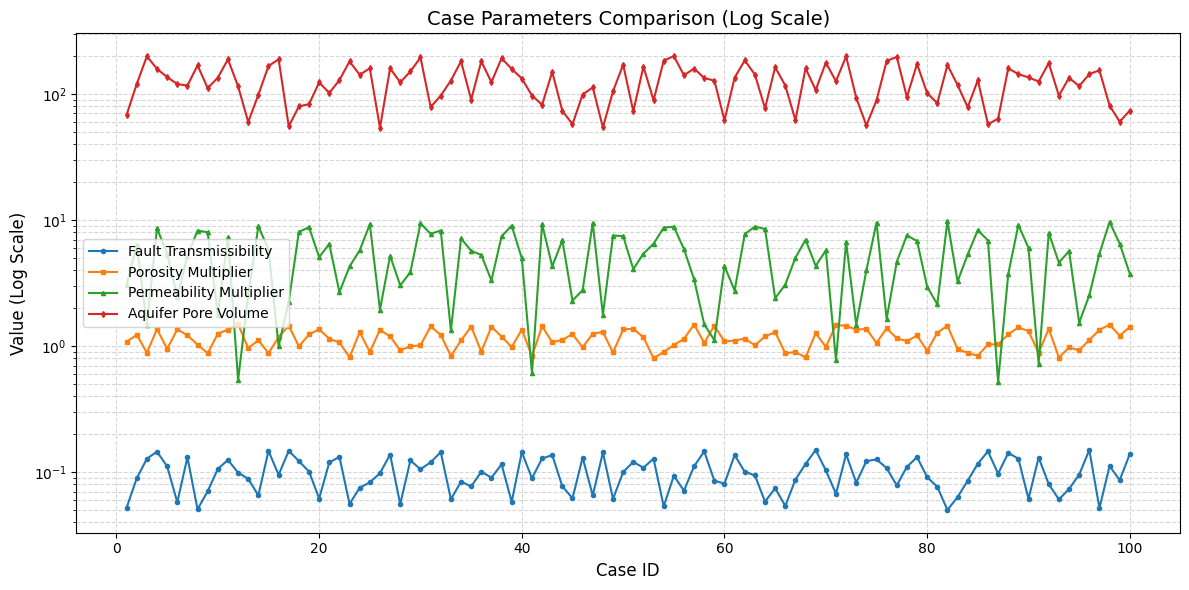

In [ ]:
import matplotlib.pyplot as plt

# Set the figure size
plt.figure(figsize=(12, 6))

# Plot each parameter from EDA_cases
plt.plot(EDA_cases['case_id'], EDA_cases['fault_trans'], label='Fault Transmissibility', marker='o', markersize=3)
plt.plot(EDA_cases['case_id'], EDA_cases['poro_mult'], label='Porosity Multiplier', marker='s', markersize=3)
plt.plot(EDA_cases['case_id'], EDA_cases['perm_mult'], label='Permeability Multiplier', marker='^', markersize=3)
plt.plot(EDA_cases['case_id'], EDA_cases['aquifer_pv'], label='Aquifer Pore Volume', marker='d', markersize=3)

# Use logarithmic scale on Y-axis because the ranges are vastly different
plt.yscale('log')

# Formatting the plot
plt.title('Case Parameters Comparison (Log Scale)', fontsize=14)
plt.xlabel('Case ID', fontsize=12)
plt.ylabel('Value (Log Scale)', fontsize=12)
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend(fontsize=10)

# Show the plot
plt.tight_layout()
plt.show()

Note: Permeability value has significant volatility? Or maybe it just has a bigger variance?

In [ ]:
# Define the columns we want to summarize
params_cols = ['fault_trans', 'poro_mult', 'perm_mult', 'aquifer_pv']

# Calculate the required statistics
summary_stats = EDA_cases[params_cols].agg(['min', 'max', 'mean', 'var', 'std']).T

# Rename columns for clarity
summary_stats.columns = ['Min', 'Max', 'Average', 'Variance', 'Standard Deviation']

# Display the formatted summary table
display(summary_stats)

,Min,Max,Average,Variance,Standard Deviation
fault_trans,0.050109,0.149950,0.099557,0.000905,0.030082
poro_mult,0.801219,1.494027,1.148462,0.041643,0.204066
perm_mult,0.520527,9.784546,5.199829,7.434857,2.726693
aquifer_pv,53.952910,199.835200,125.165908,1795.195763,42.369751


In [ ]:
# Calculate the correlation matrix for the four parameters
correlation_matrix = EDA_cases[params_cols].corr()

# Display the correlation matrix
display(correlation_matrix)

,fault_trans,poro_mult,perm_mult,aquifer_pv
fault_trans,1.000000,0.140480,-0.044257,-0.007455
poro_mult,0.140480,1.000000,-0.014435,-0.068147
perm_mult,-0.044257,-0.014435,1.000000,0.175679
aquifer_pv,-0.007455,-0.068147,0.175679,1.000000


Correlation pair: Perm and aquifer, porous and fault.

Note: Maybe we can use this pairing for feature engineering later???



```
# This is formatted as code
```

3.2 EDA for production simulation

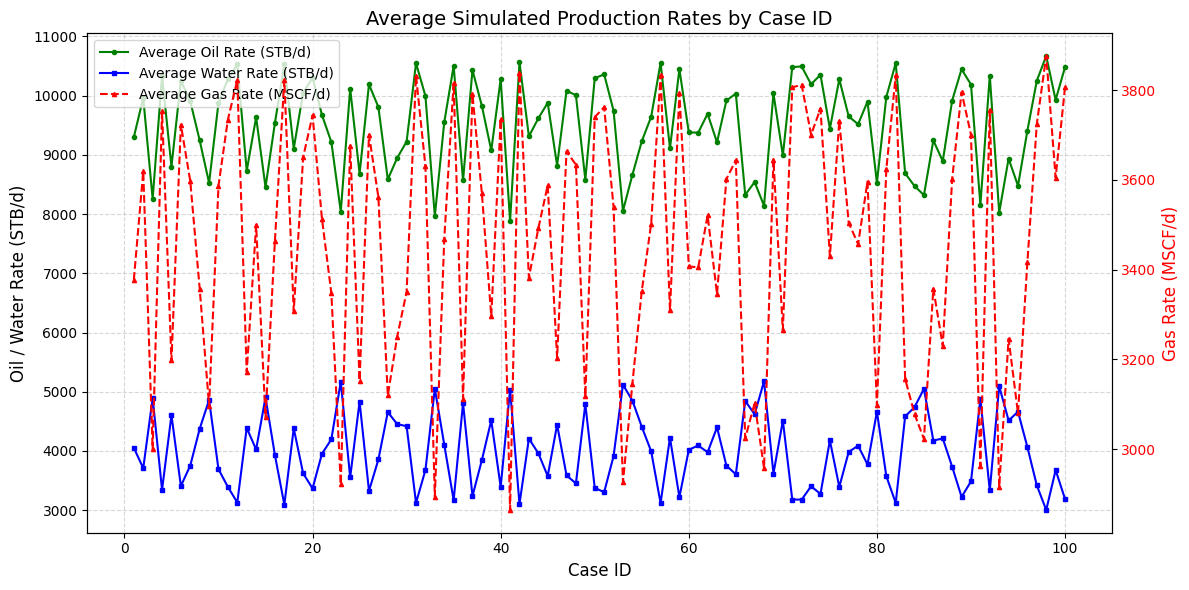

In [ ]:
import matplotlib.pyplot as plt

# Group by case_id to get the average simulated rates over the production lifetime
case_prod = EDA_prod.groupby('case_id')[['oil_rate', 'gas_rate', 'water_rate']].mean().reset_index()

# Plot the average production rates per case_id
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot Oil and Water Rates on the left Y-axis
ax1.plot(case_prod['case_id'], case_prod['oil_rate'], label='Average Oil Rate (STB/d)', color='green', marker='o', markersize=3, linewidth=1.5)
ax1.plot(case_prod['case_id'], case_prod['water_rate'], label='Average Water Rate (STB/d)', color='blue', marker='s', markersize=3, linewidth=1.5)
ax1.set_xlabel('Case ID', fontsize=12)
ax1.set_ylabel('Oil / Water Rate (STB/d)', color='black', fontsize=12)
ax1.tick_params(axis='y', labelcolor='black')
ax1.grid(True, linestyle='--', alpha=0.5)

# Create a second Y-axis for Gas Rate
ax2 = ax1.twinx()
ax2.plot(case_prod['case_id'], case_prod['gas_rate'], label='Average Gas Rate (MSCF/d)', color='red', linestyle='--', marker='^', markersize=3, linewidth=1.5)
ax2.set_ylabel('Gas Rate (MSCF/d)', color='red', fontsize=12)
ax2.tick_params(axis='y', labelcolor='red')

# Combine legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=10)

plt.title('Average Simulated Production Rates by Case ID', fontsize=14)
plt.tight_layout()
plt.show()

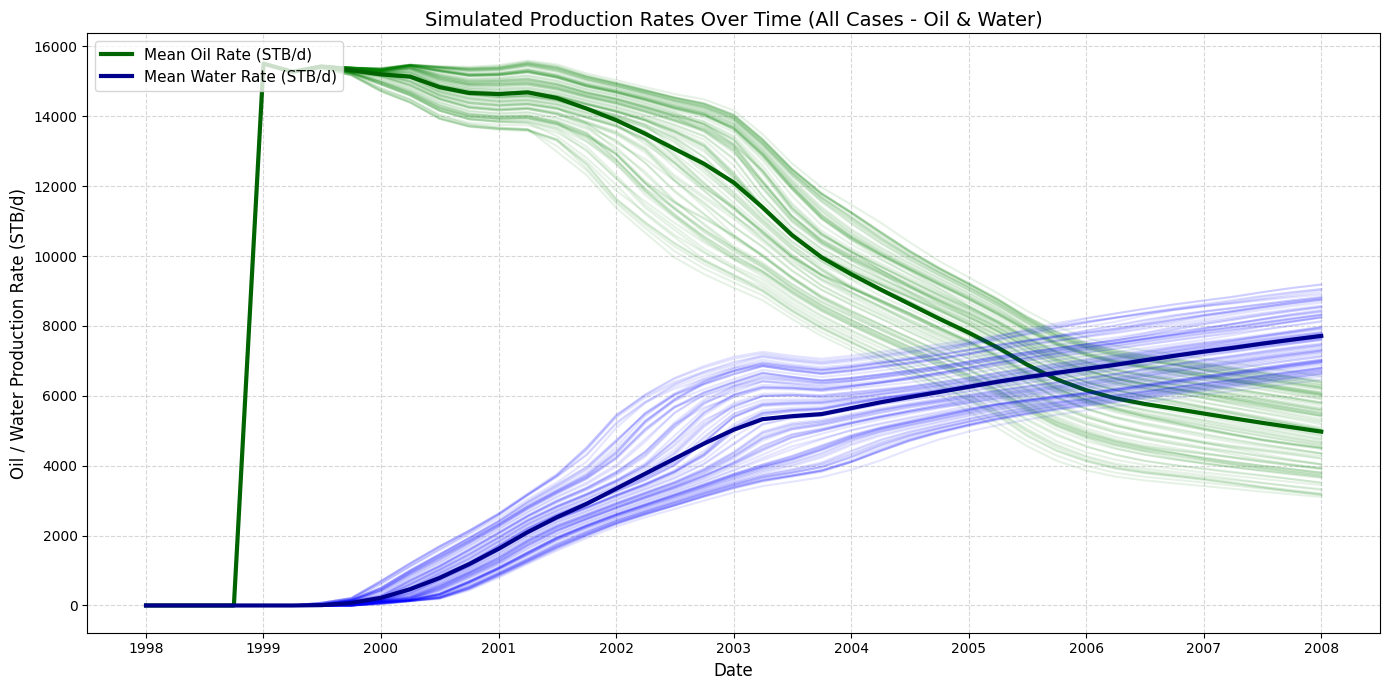

In [ ]:
import matplotlib.pyplot as plt

# Configuration switch to easily enable/disable gas rate plotting
plot_gas = False

# Pivot the production data so dates are rows and case_ids are columns
pivoted_oil = EDA_prod.pivot(index='date', columns='case_id', values='oil_rate')
pivoted_water = EDA_prod.pivot(index='date', columns='case_id', values='water_rate')

if plot_gas:
    pivoted_gas = EDA_prod.pivot(index='date', columns='case_id', values='gas_rate')

# Create a visualization of the pivoted and merged case profiles
fig, ax1 = plt.subplots(figsize=(14, 7))

# Plot individual oil & water cases with low opacity and their average in bold on the left axis
for col in pivoted_oil.columns:
    ax1.plot(pivoted_oil.index, pivoted_oil[col], color='green', alpha=0.1)
line_oil, = ax1.plot(pivoted_oil.index, pivoted_oil.mean(axis=1), color='darkgreen', linewidth=3, label='Mean Oil Rate (STB/d)')

for col in pivoted_water.columns:
    ax1.plot(pivoted_water.index, pivoted_water[col], color='blue', alpha=0.1)
line_water, = ax1.plot(pivoted_water.index, pivoted_water.mean(axis=1), color='darkblue', linewidth=3, label='Mean Water Rate (STB/d)')

ax1.set_xlabel('Date', fontsize=12)
ax1.set_ylabel('Oil / Water Production Rate (STB/d)', color='black', fontsize=12)
ax1.tick_params(axis='y', labelcolor='black')
ax1.grid(True, linestyle='--', alpha=0.5)

# Handle gas line visualization inside a conditional block
if plot_gas:
    # Create a secondary axis for the Gas Rate (MSCF/d)
    ax2 = ax1.twinx()
    for col in pivoted_gas.columns:
        ax2.plot(pivoted_gas.index, pivoted_gas[col], color='red', alpha=0.08)
    line_gas, = ax2.plot(pivoted_gas.index, pivoted_gas.mean(axis=1), color='darkred', linestyle='--', linewidth=3, label='Mean Gas Rate (MSCF/d)')

    ax2.set_ylabel('Gas Production Rate (MSCF/d)', color='darkred', fontsize=12)
    ax2.tick_params(axis='y', labelcolor='darkred')

    # Combine legends from both axes
    lines = [line_oil, line_water, line_gas]
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc='upper left', fontsize=11)
else:
    # Legend for oil and water only
    ax1.legend(loc='upper left', fontsize=11)

plt.title('Simulated Production Rates Over Time (All Cases - Oil, Water, & Gas)' if plot_gas else 'Simulated Production Rates Over Time (All Cases - Oil & Water)', fontsize=14)
plt.tight_layout()
plt.show()

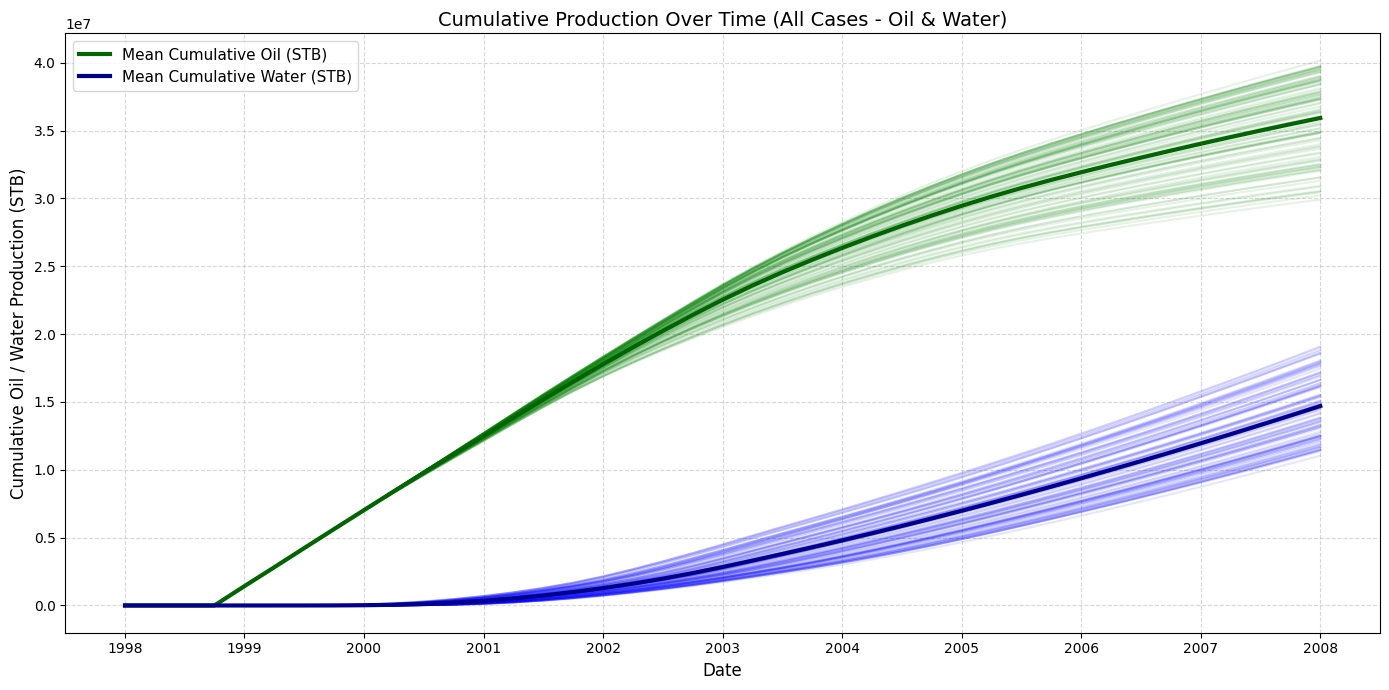

In [ ]:
import matplotlib.pyplot as plt

# Configuration switch to easily enable/disable gas cumulative plotting
plot_gas = False

# Pivot the cumulative production data so dates are rows and case_ids are columns
pivoted_oil_cum = EDA_prod.pivot(index='date', columns='case_id', values='oil_cum')
pivoted_water_cum = EDA_prod.pivot(index='date', columns='case_id', values='water_cum')

if plot_gas:
    pivoted_gas_cum = EDA_prod.pivot(index='date', columns='case_id', values='gas_cum')

# Create a visualization of the pivoted and merged cumulative case profiles
fig, ax1 = plt.subplots(figsize=(14, 7))

# Plot individual oil & water cumulative cases with low opacity and their average in bold on the left axis
for col in pivoted_oil_cum.columns:
    ax1.plot(pivoted_oil_cum.index, pivoted_oil_cum[col], color='green', alpha=0.1)
line_oil, = ax1.plot(pivoted_oil_cum.index, pivoted_oil_cum.mean(axis=1), color='darkgreen', linewidth=3, label='Mean Cumulative Oil (STB)')

for col in pivoted_water_cum.columns:
    ax1.plot(pivoted_water_cum.index, pivoted_water_cum[col], color='blue', alpha=0.1)
line_water, = ax1.plot(pivoted_water_cum.index, pivoted_water_cum.mean(axis=1), color='darkblue', linewidth=3, label='Mean Cumulative Water (STB)')

ax1.set_xlabel('Date', fontsize=12)
ax1.set_ylabel('Cumulative Oil / Water Production (STB)', color='black', fontsize=12)
ax1.tick_params(axis='y', labelcolor='black')
ax1.grid(True, linestyle='--', alpha=0.5)

# Handle gas cumulative line visualization inside a conditional block
if plot_gas:
    # Create a secondary axis for the Cumulative Gas (MSCF)
    ax2 = ax1.twinx()
    for col in pivoted_gas_cum.columns:
        ax2.plot(pivoted_gas_cum.index, pivoted_gas_cum[col], color='red', alpha=0.08)
    line_gas, = ax2.plot(pivoted_gas_cum.index, pivoted_gas_cum.mean(axis=1), color='darkred', linestyle='--', linewidth=3, label='Mean Cumulative Gas (MSCF)')

    ax2.set_ylabel('Cumulative Gas Production (MSCF)', color='darkred', fontsize=12)
    ax2.tick_params(axis='y', labelcolor='darkred')

    # Combine legends from both axes
    lines = [line_oil, line_water, line_gas]
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc='upper left', fontsize=11)
else:
    # Legend for oil and water only
    ax1.legend(loc='upper left', fontsize=11)

plt.title('Cumulative Production Over Time (All Cases - Oil, Water, & Gas)' if plot_gas else 'Cumulative Production Over Time (All Cases - Oil & Water)', fontsize=14)
plt.tight_layout()
plt.show()

Note: Gas and oil rate move in the same direction, but have different magnitude multiplier. Keep this in mind for the proxy model.

3.3 EDA for real observation

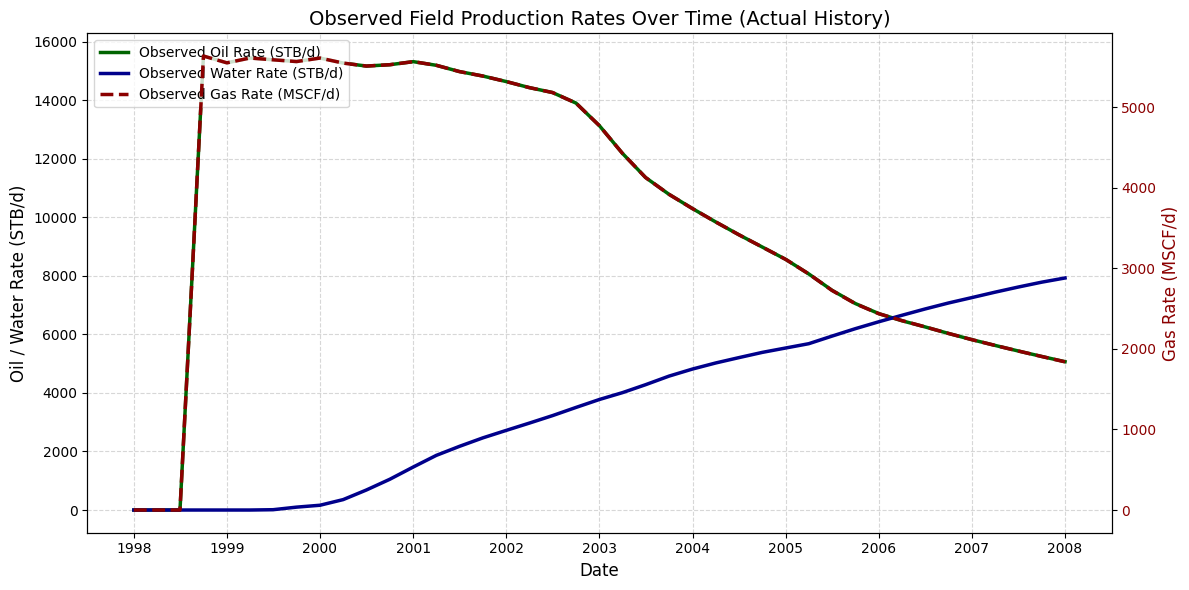

In [ ]:
import matplotlib.pyplot as plt

# Plot the observed field production rates
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot Observed Oil and Water Rates on the left Y-axis
ax1.plot(EDA_obs['date'], EDA_obs['oil_rate'], label='Observed Oil Rate (STB/d)', color='darkgreen', linewidth=2.5)
ax1.plot(EDA_obs['date'], EDA_obs['water_rate'], label='Observed Water Rate (STB/d)', color='darkblue', linewidth=2.5)
ax1.set_xlabel('Date', fontsize=12)
ax1.set_ylabel('Oil / Water Rate (STB/d)', color='black', fontsize=12)
ax1.tick_params(axis='y', labelcolor='black')
ax1.grid(True, linestyle='--', alpha=0.5)

# Create a second Y-axis for Observed Gas Rate
ax2 = ax1.twinx()
ax2.plot(EDA_obs['date'], EDA_obs['gas_rate'], label='Observed Gas Rate (MSCF/d)', color='darkred', linestyle='--', linewidth=2.5)
ax2.set_ylabel('Gas Rate (MSCF/d)', color='darkred', fontsize=12)
ax2.tick_params(axis='y', labelcolor='darkred')

# Combine legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=10)

plt.title('Observed Field Production Rates Over Time (Actual History)', fontsize=14)
plt.tight_layout()
plt.show()

Note: This is just how the real production looked like.



---

IDEA FOR PART 4: Training

Feature pairing:
- Permeability multiplier and Aquifer porous volume. (17.6%)
- Fault Transmibility and Porosity Multiplier. (14.0%)

Negative feature pairing for correction mechanism?
- Porosity multiplier and Permeability multiplier (-0.1%)
- Fault Transmibility and Aquifer porous volume (-0.7%)
- Fault Transmibility and Permeability multiplier (-4.4%)
- Porosity multiplier and Aquifer porous volume (-6.8%)


Possible Model:
- XGBoost
- Deep neural network
- LSTM

LATEST NOTE (13/10/2026):
Dataset might be too small for Deep Learning :(



---


### PART 4: Planning ahead for proxy model

Assesment (14/10/2026):


After analysis what claude left us with before its token runs out, it can be certain that the cleaned table is ready to be used for training. However, we would not take its advice directly, as it involve using Gaussian process regressors, which cannot be extrapolated into the future. We are going to use Custom RNN and pray that it works.

In [ ]:
# Custom RNN idea (by harith)
# WHAT WOULD THE MODEL DO ON EACH EPOCH:
#   1. Insert new sample from (EDA_prod[oil rate, gas rate, water rate, oil rate, gas rate, gas cum])
#   2. Insert prev sample and join with new sample (oil rate, gas rate, water rate, oil rate, gas rate, gas cum)
#     2.1 if no prev sample, use 0 as the values
#   3. Insert parameters of EDA_cases and cross multiply with the joined sample values (12 x 4 == 48)
#   4. The product of the multiplication shall be the input, while the output shall be about the next predicted sample (input: 48, hidden_1: 100, hidden_2: 100, output: 12)
#   5. Calculate the error value between the predicted and the real sample, and use backprop as weight adjustment.


"""
# Critique of the Proposed RNN Workflow (By Gemini 3.5)

### 1. Sequential Input (Steps 1 & 2)
* **Your Idea:** Combine the current/previous sample of 6 production metrics (rates and cumulatives) for oil, gas, and water, utilizing zero-padding
for the initial timestep.
* **Feedback:** **Highly logical.** This is standard autoregressive time-series behavior.
In PyTorch or Keras, this is typically handled by setting up an input tensor of shape `(batch_size, sequence_length, 6)`.

### 2. Parameter Interaction (Step 3)
* **Your Idea:** "Cross-multiply" the 12 inputs (6 current + 6 previous) with the 4 case parameters to get 48 inputs.
* **Feedback:** **Mathematical issue.** Direct element-wise cross-multiplication restricts the model's ability to learn non-linear relationships.
Instead of forced multiplication, a standard deep learning approach is to **concatenate** the static parameters with the sequential inputs
or use them to initialize the hidden state ($h_0$) of the RNN.

### 3. Model Architecture & Output (Step 4 & 5)
* **Your Idea:** Input 48 -> Hidden [100, 100, 100] -> Output 12, calculating backpropagation error based on the next actual timestep.
* **Feedback:** If you are forecasting the *next* timestep, your target output should only be **6 dimensions** (the 6 production metrics for the next quarter), not 12.

---

# Standard PyTorch LSTM Implementation for Case Production Forecasting

Here is a structurally sound, compilable PyTorch template matching your goal:

import torch
import torch.nn as nn
import numpy as np

class ReservoirLSTM(nn.Module):
    def __init__(self, static_dim=4, seq_dim=6, hidden_dim=100, output_dim=6):
        super(ReservoirLSTM, self).__init__()

        # Linear layer to project static reservoir properties into a hidden state representation
        self.static_to_hidden = nn.Linear(static_dim, hidden_dim)

        # LSTM layer tracking the temporal production changes
        self.lstm = nn.LSTM(input_size=seq_dim,
                            hidden_size=hidden_dim,
                            num_layers=3,
                            batch_first=True)

        # Fully connected layers to map hidden states to next-step output
        self.fc = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, output_dim)
        )

    def forward(self, seq_data, static_params):
        # seq_data shape: (batch, seq_len, 6)
        # static_params shape: (batch, 4)
        batch_size = seq_data.size(0)

        # Initialize hidden state using the static physical parameters of the case
        h_init = self.static_to_hidden(static_params).unsqueeze(0).repeat(3, 1, 1) # (num_layers, batch, hidden)
        c_init = torch.zeros(3, batch_size, seq_data.size(-1) * 16) # cell state

        # Pass through LSTM
        lstm_out, _ = self.lstm(seq_data, (h_init, h_init)) # using initialized state

        # Predict next step values based on last hidden state sequence
        predictions = self.fc(lstm_out[:, -1, :])
        return predictions
"""

'\n# Critique of the Proposed RNN Workflow (By Gemini 3.5)\n\n### 1. Sequential Input (Steps 1 & 2)\n* **Your Idea:** Combine the current/previous sample of 6 production metrics (rates and cumulatives) for oil, gas, and water, utilizing zero-padding\nfor the initial timestep.\n* **Feedback:** **Highly logical.** This is standard autoregressive time-series behavior.\nIn PyTorch or Keras, this is typically handled by setting up an input tensor of shape `(batch_size, sequence_length, 6)`.\n\n### 2. Parameter Interaction (Step 3)\n* **Your Idea:** "Cross-multiply" the 12 inputs (6 current + 6 previous) with the 4 case parameters to get 48 inputs.\n* **Feedback:** **Mathematical issue.** Direct element-wise cross-multiplication restricts the model\'s ability to learn non-linear relationships.\nInstead of forced multiplication, a standard deep learning approach is to **concatenate** the static parameters with the sequential inputs\nor use them to initialize the hidden state ($h_0$) of the RN



---



### Part 5: Custom RNN (LSTM) Dataset Preparation, Architecture, and Training Loop in PyTorch

To train our model, we must prepare:
1. **Static Physical Parameters (`static_params`)**: Shape `(100, 4)` scaled using standard normalization on the training split.
2. **Sequential Production Inputs (`seq_data`)**: Shape `(100, sequence_length, 6)` mapping the rates and cumulatives for Oil, Gas, and Water.
3. **Sequential Target Outputs (`targets`)**: Shape `(100, sequence_length, 6)` matching the shifted next-timestep actual metrics.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

PARAMS  = ['fault_trans', 'poro_mult', 'perm_mult', 'aquifer_pv']

# 1. Sort datasets to ensure correct alignment of cases
cases_df = EDA_cases.sort_values('case_id').reset_index(drop=True)
prod_df = EDA_prod.sort_values(['case_id', 'date']).reset_index(drop=True)

# 2. Extract and Scale Static Features (Fit Scaler using train split only)
train_mask = (cases_df['split'] == 'train').values
val_mask = (cases_df['split'] == 'val').values
test_mask = (cases_df['split'] == 'test').values

scaler_static = StandardScaler()
scaler_static.fit(cases_df.loc[train_mask, PARAMS])
static_scaled = scaler_static.transform(cases_df[PARAMS])

# 3. Shape Temporal Sequences for each of the 100 cases
seq_cols = ['oil_rate', 'gas_rate', 'water_rate', 'oil_cum', 'gas_cum', 'water_cum']
n_cases = 100
n_timesteps = 41 # 41 unique dates
n_features = len(seq_cols)

# Fit temporal scale factors from the training subset
scaler_seq = StandardScaler()
scaler_seq.fit(prod_df[prod_df['case_id'].isin(cases_df.loc[train_mask, 'case_id'])][seq_cols])
prod_scaled = scaler_seq.transform(prod_df[seq_cols])

# Reshape sequences to (100, 41, 6)
sequences = prod_scaled.reshape(n_cases, n_timesteps, n_features)

# For step-by-step sequential forecasting:
# Inputs: sequence from index 0 to T-1
# Targets: sequence from index 1 to T
seq_inputs = sequences[:, :-1, :]
seq_targets = sequences[:, 1:, :]

# Convert everything to PyTorch Tensors
X_static = torch.tensor(static_scaled, dtype=torch.float32)
X_seq = torch.tensor(seq_inputs, dtype=torch.float32)
Y_seq = torch.tensor(seq_targets, dtype=torch.float32)

print("Static Properties Tensor Shape:", X_static.shape)
print("Sequence Inputs Tensor Shape:", X_seq.shape)
print("Sequence Targets Tensor Shape:", Y_seq.shape)

Static Properties Tensor Shape: torch.Size([100, 4])
Sequence Inputs Tensor Shape: torch.Size([100, 40, 6])
Sequence Targets Tensor Shape: torch.Size([100, 40, 6])


In [ ]:
class ReservoirDataset(Dataset):
    def __init__(self, static, seq_in, seq_target):
        self.static = static
        self.seq_in = seq_in
        self.seq_target = seq_target

    def __len__(self):
        return len(self.static)

    def __getitem__(self, idx):
        return self.static[idx], self.seq_in[idx], self.seq_target[idx]

# Build splits based on the case splits masks
train_dataset = ReservoirDataset(X_static[train_mask], X_seq[train_mask], Y_seq[train_mask])
val_dataset = ReservoirDataset(X_static[val_mask], X_seq[val_mask], Y_seq[val_mask])
test_dataset = ReservoirDataset(X_static[test_mask], X_seq[test_mask], Y_seq[test_mask])

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=8, shuffle=False)

In [ ]:
class ReservoirLSTM(nn.Module):
    def __init__(self, static_dim=4, seq_dim=6, hidden_dim=64, num_layers=2, output_dim=6):
        super(ReservoirLSTM, self).__init__()
        self.num_layers = num_layers
        self.hidden_dim = hidden_dim

        # Map 4 static variables to h_0 initializer dimensions
        self.static_to_hidden = nn.Linear(static_dim, hidden_dim * num_layers)
        self.static_to_cell = nn.Linear(static_dim, hidden_dim * num_layers)

        self.lstm = nn.LSTM(input_size=seq_dim,
                            hidden_size=hidden_dim,
                            num_layers=num_layers,
                            batch_first=True)

        self.fc = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, output_dim)
        )

    def forward(self, static_params, seq_data):
        # seq_data shape: (batch_size, sequence_length, 6)
        batch_size = seq_data.size(0)

        # Project and reshape to format (num_layers, batch_size, hidden_dim)
        h_init = self.static_to_hidden(static_params).view(batch_size, self.num_layers, self.hidden_dim).transpose(0, 1).contiguous()
        c_init = self.static_to_cell(static_params).view(batch_size, self.num_layers, self.hidden_dim).transpose(0, 1).contiguous()

        # Propagate through LSTM
        lstm_out, _ = self.lstm(seq_data, (h_init, c_init))

        # Predict sequential targets at each sequence step
        predictions = self.fc(lstm_out)
        return predictions

model = ReservoirLSTM()
print(model)

ReservoirLSTM(
  (static_to_hidden): Linear(in_features=4, out_features=128, bias=True)
  (static_to_cell): Linear(in_features=4, out_features=128, bias=True)
  (lstm): LSTM(6, 64, num_layers=2, batch_first=True)
  (fc): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=6, bias=True)
  )
)


In [ ]:
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.005, weight_decay=1e-5)

epochs = 150
train_losses, val_losses = [], []

for epoch in range(epochs):
    model.train()
    train_loss = 0.0
    for batch_static, batch_seq_in, batch_target in train_loader:
        optimizer.zero_grad()
        outputs = model(batch_static, batch_seq_in)
        loss = criterion(outputs, batch_target)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * batch_static.size(0)

    train_loss /= len(train_loader.dataset)
    train_losses.append(train_loss)

    # Validation step
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for batch_static, batch_seq_in, batch_target in val_loader:
            outputs = model(batch_static, batch_seq_in)
            loss = criterion(outputs, batch_target)
            val_loss += loss.item() * batch_static.size(0)
    val_loss /= len(val_loader.dataset)
    val_losses.append(val_loss)

    if (epoch + 1) % 25 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:03d}/{epochs} | Train Loss: {train_loss:.6f} | Val Loss: {val_loss:.6f}")

Epoch 001/150 | Train Loss: 0.672446 | Val Loss: 0.297593
Epoch 025/150 | Train Loss: 0.000727 | Val Loss: 0.000677
Epoch 050/150 | Train Loss: 0.000794 | Val Loss: 0.000320
Epoch 075/150 | Train Loss: 0.000659 | Val Loss: 0.000524
Epoch 100/150 | Train Loss: 0.000317 | Val Loss: 0.000267
Epoch 125/150 | Train Loss: 0.000444 | Val Loss: 0.000453
Epoch 150/150 | Train Loss: 0.000341 | Val Loss: 0.000265


In [ ]:
# Evaluate performance on test set
criterion = nn.MSELoss()
model.eval()
test_loss = 0.0
predictions_list, targets_list = [], []

with torch.no_grad():
    for batch_static, batch_seq_in, batch_target in test_loader:
        outputs = model(batch_static, batch_seq_in)
        loss = criterion(outputs, batch_target)
        test_loss += loss.item() * batch_static.size(0)

        predictions_list.append(outputs.numpy())
        targets_list.append(batch_target.numpy())

test_loss /= len(test_loader.dataset)
print(f"Final Normalized Test MSE Loss: {test_loss:.6f}")

Final Normalized Test MSE Loss: 0.000300


In [ ]:
'''Only uncommnent this if you can get LSTM model with Test MSE lower than the current lowest ones!'''

# Current Lowest MSE: 0.000177

#import torch

# Save the trained model state dict
#torch.save(model.state_dict(), 'reservoir_lstm.pth')
#print("Model weights successfully saved to 'reservoir_lstm.pth'!")

'Only uncommnent this if you can get LSTM model with Test MSE lower than the current lowest ones!'



---

### PART 6: Proxy model testing and evaluation

In [ ]:
#Load Model from github
import torch
import urllib.request
import io
from google.colab import userdata

# Initialize the model architecture
model = ReservoirLSTM(static_dim=4, seq_dim=6, hidden_dim=64, num_layers=2, output_dim=6)

github_token = userdata.get('GITHUB_TOKEN')
headers = {'Authorization': f'token {github_token}'}

# URL to the pre-trained weights
model_url = 'https://raw.githubusercontent.com/HarithMarzuki/private_dataset/main/models/reservoirLSTM_1.pth'

try:
    # Create Request object to include authentication headers
    req = urllib.request.Request(model_url, headers=headers)

    # Download the weights into memory
    with urllib.request.urlopen(req) as response:
        buffer = io.BytesIO(response.read())
        state_dict = torch.load(buffer, map_location=torch.device('cpu'))

    # Load state dict into model
    model.load_state_dict(state_dict)
    model.eval()
    print("Successfully loaded the pre-trained ReservoirLSTM model from GitHub!")
except Exception as e:
    print(f"An error occurred while loading the model: {e}")

Successfully loaded the pre-trained ReservoirLSTM model from GitHub!


In [ ]:
# Evaluate performance on test set
criterion = nn.MSELoss()
model.eval()
test_loss = 0.0
predictions_list, targets_list = [], []

with torch.no_grad():
    for batch_static, batch_seq_in, batch_target in test_loader:
        outputs = model(batch_static, batch_seq_in)
        loss = criterion(outputs, batch_target)
        test_loss += loss.item() * batch_static.size(0)

        predictions_list.append(outputs.numpy())
        targets_list.append(batch_target.numpy())

test_loss /= len(test_loader.dataset)
print(f"Final Normalized Test MSE Loss: {test_loss:.6f}")

Final Normalized Test MSE Loss: 0.000177


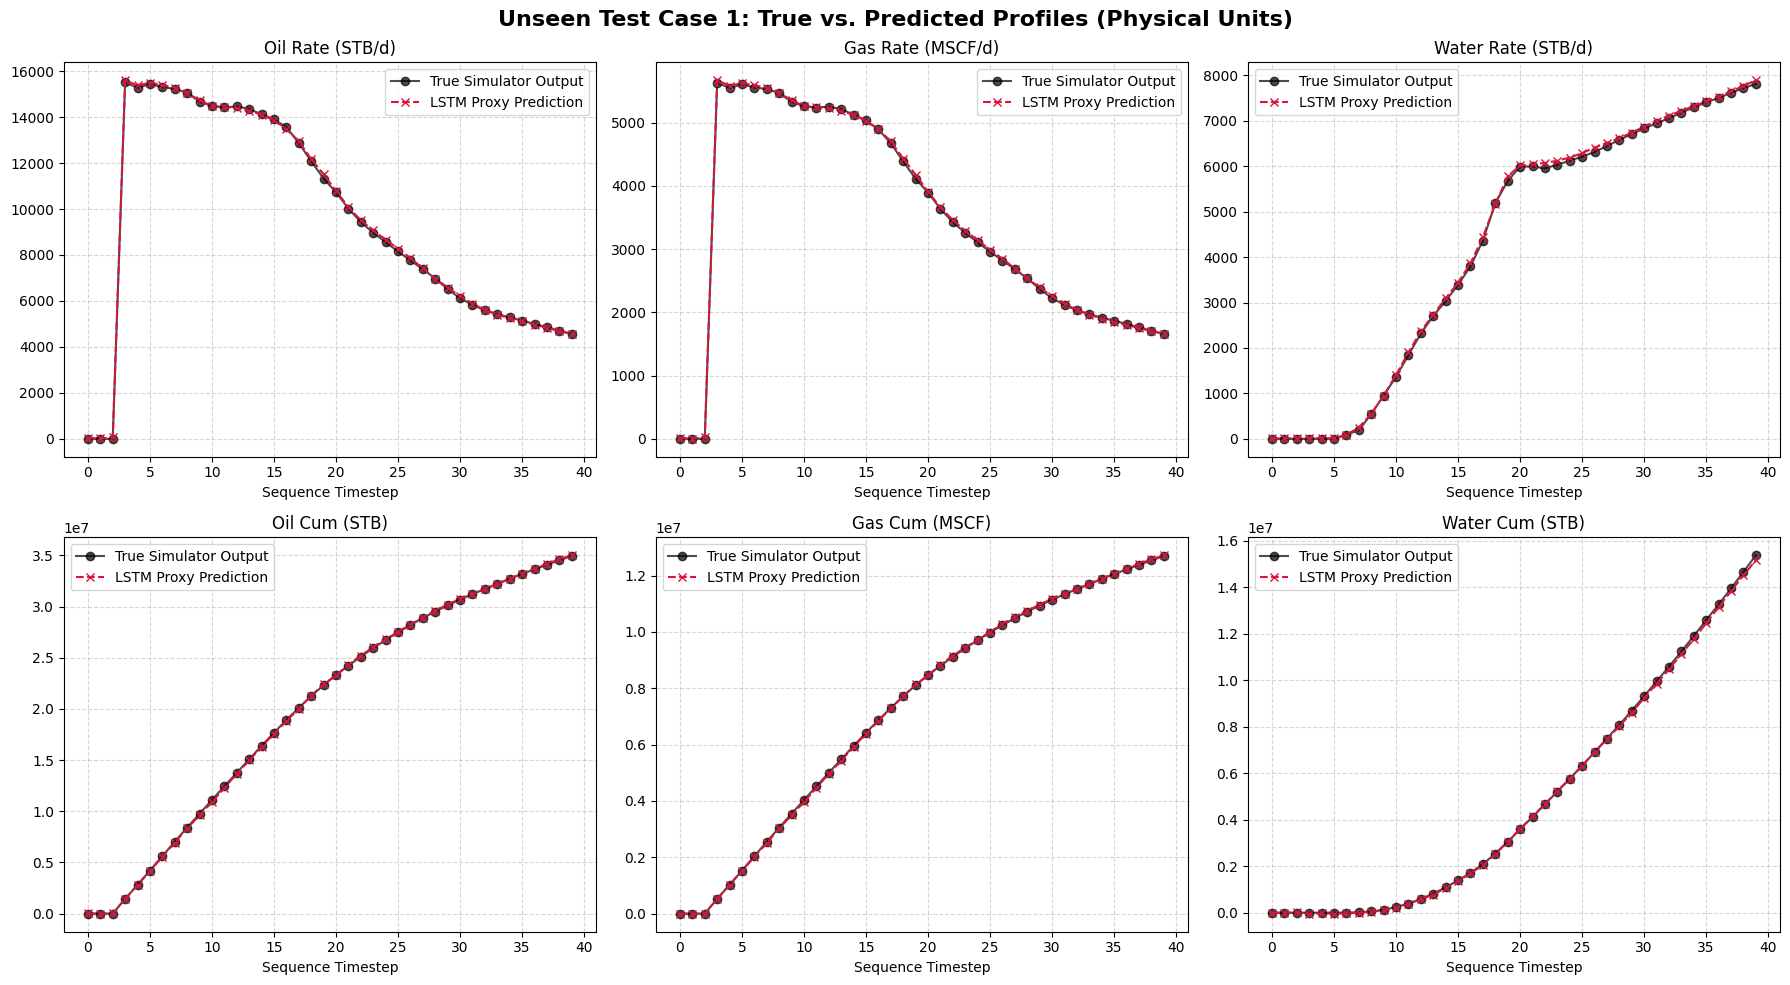

In [ ]:
import matplotlib.pyplot as plt

# 1. Reconstruct predictions and targets for test set
# concatenate batched predictions and targets
all_preds = np.concatenate(predictions_list, axis=0) # shape (15, 40, 6)
all_targets = np.concatenate(targets_list, axis=0)    # shape (15, 40, 6)

# 2. Pick a test case to visualize (e.g., the first test case, index 0)
test_case_idx = 0

# Inverse scale predictions and targets to original physical units
# scaler_seq expects a 2D array of shape (N, 6)
flat_preds = all_preds[test_case_idx]
flat_targets = all_targets[test_case_idx]

true_unscaled = scaler_seq.inverse_transform(flat_targets)
pred_unscaled = scaler_seq.inverse_transform(flat_preds)

# 3. Create Plots for Rates & Cumulative Metrics
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
metrics = ['Oil Rate (STB/d)', 'Gas Rate (MSCF/d)', 'Water Rate (STB/d)',
           'Oil Cum (STB)', 'Gas Cum (MSCF)', 'Water Cum (STB)']

for i, ax in enumerate(axes.flat):
    ax.plot(true_unscaled[:, i], label='True Simulator Output', color='black', linestyle='-', marker='o', alpha=0.7)
    ax.plot(pred_unscaled[:, i], label='LSTM Proxy Prediction', color='crimson', linestyle='--', marker='x')
    ax.set_title(metrics[i])
    ax.set_xlabel('Sequence Timestep')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend()

plt.suptitle(f"Unseen Test Case {test_case_idx + 1}: True vs. Predicted Profiles (Physical Units)", fontsize=16, weight='bold')
plt.tight_layout()
plt.show()



---

### PART 7: GP vs LSTM

Cell A: GP proxies for all six outputs, with honest scores

In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel as C
import numpy as np

#Cases dataset
PARAMS  = ['fault_trans', 'poro_mult', 'perm_mult', 'aquifer_pv']
cases = EDA_cases.sort_values('case_id').reset_index(drop=True)
X = cases[PARAMS].to_numpy()

#Target dataset
TARGETS = ['oil_cum', 'gas_cum', 'water_cum']
Y = {v: EDA_prod.pivot(index='case_id', columns='date', values=v).loc[cases.case_id].to_numpy() for v in EDA_prod}
tr, va, te = [(cases.split == s).to_numpy() for s in ('train', 'val', 'test')]
print('X', X.shape, '| Y', {v: a.shape for v, a in Y.items()}, '| train/val/test', tr.sum(), va.sum(), te.sum())

xs = StandardScaler().fit(X[tr]); Xs = xs.transform(X)           # scale with TRAIN statistics only

def fit_proxy(Yv, n_comp=4):
    scale = Yv[tr].max()
    pca = PCA(n_comp).fit(Yv[tr] / scale)
    Z = pca.transform(Yv / scale)
    gps = [GaussianProcessRegressor(C(1.0) * RBF(np.ones(X.shape[1])) + WhiteKernel(1e-3),
                                    normalize_y=True, n_restarts_optimizer=2, random_state=42).fit(Xs[tr], Z[tr, k])
           for k in range(n_comp)]
    return lambda Xnew: pca.inverse_transform(np.column_stack([g.predict(Xnew) for g in gps])) * scale

def score(true, pred):
    nrmse = np.sqrt(((true - pred) ** 2).mean()) / true.max()
    r2 = 1 - ((true - pred) ** 2).sum() / ((true - true.mean()) ** 2).sum()
    return round(nrmse, 4), round(r2, 4)

proxy = {v: fit_proxy(Y[v]) for v in TARGETS}
rows = []
for v in TARGETS:
    for name, m in (('val', va), ('test', te)):
        nr, r2 = score(Y[v][m], proxy[v](Xs[m]))
        rows.append(dict(output=v, split=name, nrmse=nr, r2=r2))
print(pd.DataFrame(rows))

X (100, 4) | Y {'date': (100, 41), 'case_id': (100, 41), 'oil_rate': (100, 41), 'gas_rate': (100, 41), 'water_rate': (100, 41), 'oil_cum': (100, 41), 'gas_cum': (100, 41), 'water_cum': (100, 41)} | train/val/test 70 15 15


/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:

      output split   nrmse   r2
0    oil_cum   val  0.0007  1.0
1    oil_cum  test  0.0005  1.0
2    gas_cum   val  0.0007  1.0
3    gas_cum  test  0.0005  1.0
4  water_cum   val  0.0007  1.0
5  water_cum  test  0.0007  1.0


/usr/local/lib/python3.13/dist-packages/sklearn/gaussian_process/kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


In [ ]:
import numpy as np, pandas as pd, warnings
warnings.filterwarnings('ignore')
ALL   = ['oil_rate','gas_rate','water_rate','oil_cum','gas_cum','water_cum']
RATES = ['oil_rate','gas_rate','water_rate']
Y = {v: EDA_prod.pivot(index='case_id', columns='date', values=v).loc[cases.case_id].to_numpy() for v in ALL}

proxy6 = {v: fit_proxy(Y[v], n_comp=6) for v in ALL}

def metrics(true, pred):                       # skip step 0, it is always 0
    true, pred = true[:, 1:], pred[:, 1:]
    nrmse = np.sqrt(((true - pred) ** 2).mean()) / true.max()
    last  = np.abs(true[:, -1] - pred[:, -1]).mean() / np.abs(true[:, -1]).mean()
    return round(nrmse, 4), round(last, 4)

rows = []
for v in ALL:
    for name, m in (('val', va), ('test', te)):
        nr, la = metrics(Y[v][m], proxy6[v](Xs[m]))
        rows.append(dict(output=v, split=name, gp_nrmse=nr, gp_last_date_rel_err=la))
gp_scores = pd.DataFrame(rows); display(gp_scores)

,output,split,gp_nrmse,gp_last_date_rel_err
0,oil_rate,val,0.0024,0.0068
1,oil_rate,test,0.0024,0.0055
2,gas_rate,val,0.0022,0.0060
3,gas_rate,test,0.0020,0.0050
4,water_rate,val,0.0030,0.0034
5,water_rate,test,0.0030,0.0040
6,oil_cum,val,0.0006,0.0007
7,oil_cum,test,0.0004,0.0006
8,gas_cum,val,0.0007,0.0007
9,gas_cum,test,0.0005,0.0006


Cell B: LSTM, free-running (no true data fed in) vs the GP

This feeds each prediction back in, so it measures what history matching will need. It uses your model, X_static, sequences and scaler_seq

In [ ]:
import torch
model.eval(); T = 41
with torch.no_grad():
    seq = torch.tensor(sequences[:, :1, :], dtype=torch.float32)      # only step 0 is given
    for _ in range(T - 1):
        nxt = model(X_static, seq)[:, -1:, :]
        seq = torch.cat([seq, nxt], dim=1)
free = scaler_seq.inverse_transform(seq.numpy().reshape(-1, 6)).reshape(100, T, 6)

rows = []
for j, v in enumerate(ALL):
    for name, m in (('val', va), ('test', te)):
        nr, la = metrics(Y[v][m], free[m][:, :, j])
        rows.append(dict(output=v, split=name, lstm_nrmse=nr, lstm_last_err=la))
cmp = pd.DataFrame(rows).merge(gp_scores, on=['output', 'split']); display(cmp)

,output,split,lstm_nrmse,lstm_last_err,gp_nrmse,gp_last_date_rel_err
0,oil_rate,val,0.0075,0.0227,0.0024,0.0068
1,oil_rate,test,0.0073,0.0232,0.0024,0.0055
2,gas_rate,val,0.0074,0.0240,0.0022,0.0060
3,gas_rate,test,0.0070,0.0248,0.0020,0.0050
4,water_rate,val,0.0137,0.0123,0.0030,0.0034
5,water_rate,test,0.0159,0.0175,0.0030,0.0040
6,oil_cum,val,0.0051,0.0087,0.0006,0.0007
7,oil_cum,test,0.0040,0.0057,0.0004,0.0006
8,gas_cum,val,0.0051,0.0084,0.0007,0.0007
9,gas_cum,test,0.0040,0.0058,0.0005,0.0006


Read it like this: if the LSTM columns are close to the GP ones, the LSTM is fine. If they are 10 times or more worse, use the GP for matching, as I suggested.

Cell C: history matching, with a blind test first

The method draws 20,000 candidate parameter sets, keeps the 20 with the lowest mismatch, then polishes the best one with differential evolution.

,0,1,2,3,4
case,86.0000,87.0000,88.0000,89.0000,90.0000
mismatch,0.0027,0.0039,0.0017,0.0013,0.0015
true_fault_trans,0.1460,0.0970,0.1420,0.1280,0.0610
true_poro_mult,1.0340,1.0320,1.2390,1.4080,1.3150
true_perm_mult,6.8800,0.5210,3.7240,9.1420,6.0060
true_aquifer_pv,57.3990,63.6840,159.4530,143.6810,135.1800
found_fault_trans,0.0550,0.1460,0.1130,0.0870,0.0850
found_poro_mult,1.0510,1.0270,1.2360,1.4070,1.3090
found_perm_mult,4.6200,1.0170,4.1070,8.4940,5.4380
found_aquifer_pv,77.4060,67.3480,149.8950,130.9120,103.1890


,fault_trans,poro_mult,perm_mult,aquifer_pv,mismatch
0,0.117852,1.315704,0.796864,192.430102,0.129804
1,0.067726,1.310914,1.012163,192.831208,0.129818
2,0.079815,1.315638,0.623649,162.994963,0.129819
3,0.114513,1.315208,0.537173,165.425694,0.129819
4,0.055925,1.315939,0.775418,161.590121,0.129822
5,0.092137,1.316547,0.691834,159.836768,0.129823
6,0.111777,1.306118,1.149111,166.335825,0.129828
7,0.099659,1.306523,1.318280,169.924380,0.129829
8,0.118171,1.307254,1.227122,162.394674,0.129829
9,0.110762,1.318030,0.800796,159.208463,0.129830


best: {'fault_trans': np.float64(0.118), 'poro_mult': np.float64(1.316), 'perm_mult': np.float64(0.797), 'aquifer_pv': np.float64(192.43)} | mismatch 0.1298


,fault_trans,poro_mult,perm_mult,aquifer_pv,mismatch
min,0.054742,1.30296,0.537173,152.092624,0.129804
max,0.143404,1.31803,1.594611,198.256050,0.129844
std,0.023942,0.00491,0.307637,14.533707,0.000010


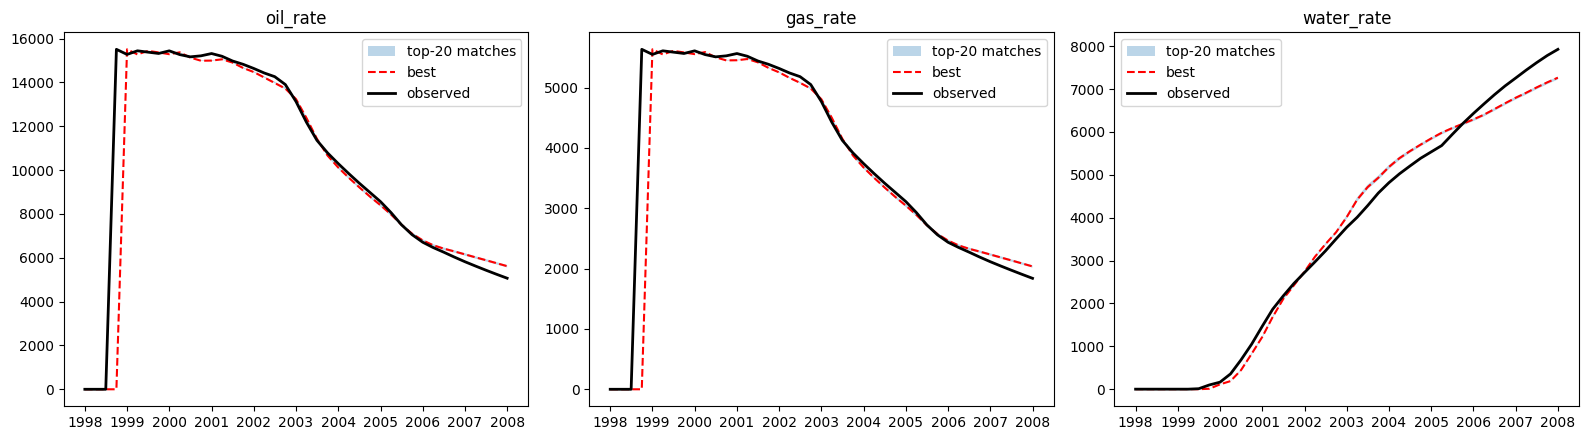

In [ ]:
from scipy.stats import qmc
from scipy.optimize import differential_evolution
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

assert (EDA_obs['date'].values == np.sort(EDA_prod['date'].unique())).all(), 'observed dates differ from the grid'
# Explicitly cast to float to prevent object array TypeError
lo, hi = X.min(0).astype(float), X.max(0).astype(float)

# Ensure target arrays in Y are cast to float64 to avoid object dtype issues during math operations
Y_numeric = {v: Y[v].astype(np.float64) for v in Y}

def mismatch(Xs_batch, obs_dict):
    e = 0
    for v in RATES:
        true_val = obs_dict[v].astype(np.float64)
        pred_val = proxy6[v](Xs_batch).astype(np.float64)
        e = e + (((pred_val - true_val) / true_val.max()) ** 2).mean(axis=1)
    return np.sqrt(e / len(RATES))

def match(obs_dict, n_samples=20000, seed=0, top=20):
    cand = lo + qmc.LatinHypercube(d=4, seed=seed).random(n_samples) * (hi - lo)
    err = mismatch(xs.transform(cand), obs_dict); order = np.argsort(err)[:top]
    f = lambda Xt: mismatch(xs.transform(Xt.T), obs_dict)
    de = differential_evolution(f, list(zip(lo, hi)), x0=cand[order[0]], seed=seed, maxiter=60,
                                popsize=12, vectorized=True, updating='deferred', polish=False)
    return cand[order], err[order], de.x, de.fun

# 1) BLIND TEST: treat test cases as the "observed" history, can we recover their parameters?
rows = []
for cid in cases.loc[te, 'case_id'].values[:5]:
    i = cid - 1
    blind_obs = {v: Y_numeric[v][i] for v in RATES}
    ens, eerr, bx, bf = match(blind_obs)
    rows.append(dict(case=cid, mismatch=round(bf, 4),
                     **{f'true_{p}': round(X[i, j], 3) for j, p in enumerate(PARAMS)},
                     **{f'found_{p}': round(bx[j], 3) for j, p in enumerate(PARAMS)}))
display(pd.DataFrame(rows).T)

# 2) REAL MATCH on the observed history
obs = {v: EDA_obs[v].to_numpy().astype(np.float64) for v in RATES}
ens, eerr, bx, bf = match(obs)
best = pd.DataFrame(ens, columns=PARAMS); best['mismatch'] = eerr
display(best.head(10)); print('best:', dict(zip(PARAMS, bx.round(3))), '| mismatch', round(bf, 4))
display(best.describe().loc[['min', 'max', 'std']])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, v in zip(axes, RATES):
    c = proxy6[v](xs.transform(ens))
    ax.fill_between(EDA_obs['date'], c.min(0).astype(np.float64), c.max(0).astype(np.float64), alpha=.3, label='top-20 matches')
    ax.plot(EDA_obs['date'], proxy6[v](xs.transform(bx[None, :]))[0], 'r--', label='best')
    ax.plot(EDA_obs['date'], obs[v], 'k', lw=2, label='observed'); ax.set_title(v); ax.legend()
plt.tight_layout(); plt.show()
best.to_parquet('history_match_top20.parquet')

On synthetic data the blind test recovered porosity and aquifer volume almost exactly. Fault transmissibility and permeability were not recovered. Different parameter combinations gave nearly the same curves, and the spread of the top-20 matches shows this. That is normal in history matching. It is also what the organizers want to see as uncertainty, so keep the spread and don’t only report the best case.

Retrain on the first 30 steps only (1998–2005) and roll out the last 10 steps (2005–2008) for the val and test cases. Hide those final steps completely. That score tells you how far the recursion can be trusted. If it is bad over 10 steps, 80 steps will be worse, and that decides whether the LSTM is usable for the forecast at all.

In [ ]:
import torch
import numpy as np
import pandas as pd

n_future = 80                                   # 2008-04-01 ... 2028-01-01, quarterly
best = pd.read_parquet('history_match_top20.parquet')      # saved by Cell C
S = torch.tensor(scaler_static.transform(best[PARAMS].to_numpy()), dtype=torch.float32)
model.eval()
with torch.no_grad():
    seq = torch.tensor(sequences[:1, :1, :], dtype=torch.float32).repeat(len(best), 1, 1)  # step 0
    for _ in range(40 + n_future):
        seq = torch.cat([seq, model(S, seq)[:, -1:, :]], dim=1)
fc = scaler_seq.inverse_transform(seq.numpy().reshape(-1, 6)).reshape(len(best), -1, 6)
rates = np.clip(fc[:, 41:, :3], 0, None)        # future rates only: oil, gas, water
dates = pd.date_range('2008-04-01', periods=n_future, freq='QS')

# Create a unified DatetimeIndex to ensure diff works on a clean datetime64 array
all_dates = pd.DatetimeIndex([pd.Timestamp('2008-01-01')]).union(dates)
days = np.diff(all_dates.to_numpy()).astype('timedelta64[D]').astype(float)

cum0 = EDA_obs[['oil_cum', 'gas_cum', 'water_cum']].iloc[-1].to_numpy()    # derived, approximate
cum = cum0 + np.cumsum(rates * days[None, :, None], axis=1)                # rate x days per step

rates (20, 80, 3) | cum (20, 80, 3)
negative rates clipped: 0
cum oil at 2028: min/median/max = 66200490.25063868 66305987.95718165 66399877.21279688


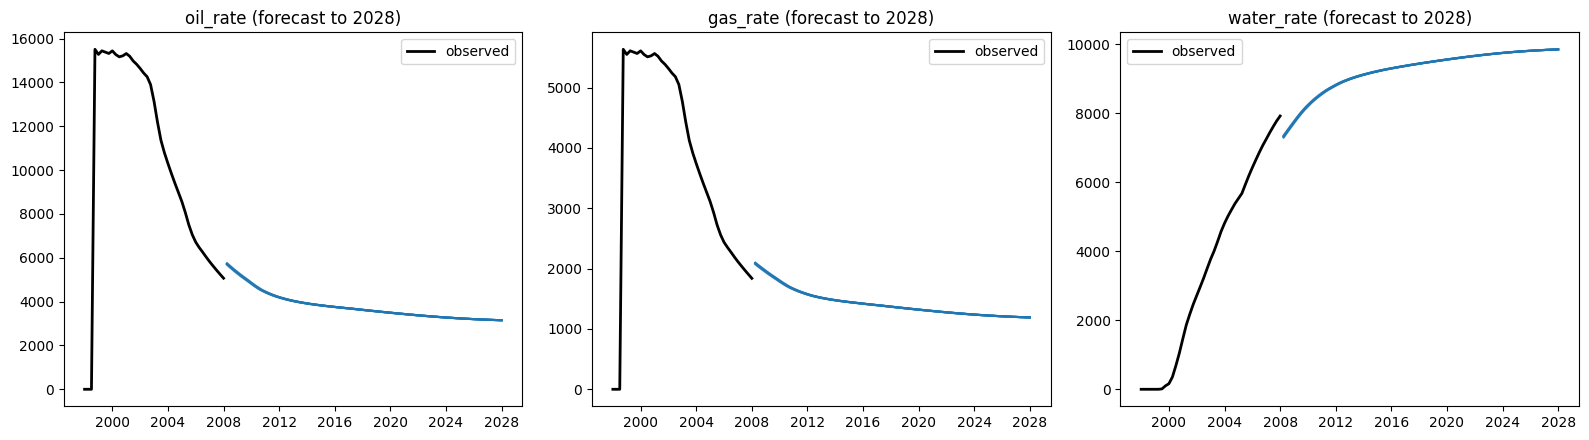

,member,date,gas_cum_MSCF,oil_cum_STB,water_cum_STB
0,1,2008-04-01,1.421845e+07,3.913561e+07,1.384318e+07
1,1,2008-07-01,1.440426e+07,3.964342e+07,1.452281e+07
2,1,2008-10-01,1.458801e+07,4.014441e+07,1.522278e+07
3,1,2009-01-01,1.476782e+07,4.063349e+07,1.593535e+07
4,1,2009-04-01,1.493999e+07,4.110085e+07,1.664431e+07


In [ ]:
import matplotlib.pyplot as plt

# 1) Look at the numbers
print('rates', rates.shape, '| cum', cum.shape)          # expect (20, 80, 3) each (20 ensemble members, 80 quarters, 3 streams)
print('negative rates clipped:', int((fc[:, 41:, :3] < 0).sum()))
print('cum oil at 2028: min/median/max =', cum[:, -1, 0].min(), np.median(cum[:, -1, 0]), cum[:, -1, 0].max())

# 2) Plot history (observed) + forecast ensemble
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for j, (ax, nm) in enumerate(zip(axes, ['oil_rate', 'gas_rate', 'water_rate'])):
    for k in range(rates.shape[0]):
        ax.plot(dates, rates[k, :, j], color='tab:blue', alpha=.25)
    ax.plot(EDA_obs['date'], EDA_obs[nm], 'k', lw=2, label='observed')
    ax.set_title(nm + ' (forecast to 2028)'); ax.legend()
plt.tight_layout(); plt.show()

# 3) Build the template-shaped table (one row per quarter, one block per ensemble member)
out = pd.concat([
    pd.DataFrame({'member': k + 1, 'date': dates,
                  'gas_cum_MSCF': cum[k, :, 1], 'oil_cum_STB': cum[k, :, 0], 'water_cum_STB': cum[k, :, 2]})
    for k in range(cum.shape[0])], ignore_index=True)
out.to_parquet('forecast_ensemble.parquet'); display(out.head())

This is a good first result, but I wouldn’t submit it yet. The plot shows three problems.

The forecast doesn’t start where history ends. At 2008 observed oil ends near 5,000 and the forecast starts near 5,600. Gas goes from about 1,800 to 2,050, and water from 7,900 to 7,350. The model rolls out from its own matched 1998–2008 curve, which is about 10% off the real last point. A forecast should start from the real last state.
All 20 members are almost identical. Cumulative oil at 2028 ranges only from 64.48M to 64.83M, so the ensemble gives no real uncertainty. Either the top-20 matches are neighbours of the same point, or the LSTM largely ignores the four parameters, since they only set its starting state.
Every curve flattens at a constant rate. Oil settles near 3,100 STB/d and water near 9,700, and both stay there until 2028. Observed oil is still falling steeply at 2008, so I doubt a flat plateau. A recursive LSTM settling into a fixed point is the typical failure when it is pushed beyond what it was trained on.

Cell D: history matching on rates, cumulative, and both

This replaces the mismatch and match functions from Cell C with versions that take a list of outputs to match:

In [ ]:
CUMS = ['oil_cum', 'gas_cum', 'water_cum']

# Ensure target arrays in Y are cast to float64 to avoid object dtype issues during math operations
Y_numeric = {v: Y[v].astype(np.float64) for v in Y}

def mismatch(Xs_batch, obs, keys):
    e = 0
    for v in keys:
        # Ensure the observation is explicitly a float64 array
        true_val = obs[v].astype(np.float64)
        pred_val = proxy6[v](Xs_batch).astype(np.float64)
        e = e + (((pred_val - true_val) / true_val.max()) ** 2).mean(axis=1)
    return np.sqrt(e / len(keys))

def match(obs, keys, n_samples=20000, seed=0, top=20):
    cand = lo + qmc.LatinHypercube(d=4, seed=seed).random(n_samples) * (hi - lo)
    err = mismatch(xs.transform(cand), obs, keys); order = np.argsort(err)[:top]
    f = lambda Xt: mismatch(xs.transform(Xt.T), obs, keys)
    de = differential_evolution(f, list(zip(lo, hi)), x0=cand[order[0]], seed=seed, maxiter=60,
                                popsize=12, vectorized=True, updating='deferred', polish=False)
    return cand[order], err[order], de.x, de.fun

obs = {v: EDA_obs[v].to_numpy().astype(np.float64) for v in RATES + CUMS}
res = {}
for name, keys in {'rates': RATES, 'cumulative': CUMS, 'both': RATES + CUMS}.items():
    ens, eerr, bx, bf = match(obs, keys)
    res[name] = dict(zip(PARAMS, bx.round(3))) | {'mismatch': round(bf, 4)}
display(pd.DataFrame(res).T)

# blind test on cumulative: can we recover the parameters of a test case from its cumulative curves?
for cid in cases.loc[te, 'case_id'].values[:3]:
    i = cid - 1; _, _, bx, bf = match({v: Y_numeric[v][i] for v in CUMS}, CUMS)
    # Cast to float to avoid object array rounding issues
    true_params = X[i].astype(np.float64).round(3)
    found_params = bx.astype(np.float64).round(3)
    print(cid, 'true', true_params, '| found', found_params, '| mismatch', round(bf, 4))

,fault_trans,poro_mult,perm_mult,aquifer_pv,mismatch
rates,0.118,1.316,0.797,192.430,0.1298
cumulative,0.139,1.311,7.234,118.377,0.0136
both,0.116,1.343,0.553,196.746,0.0925


86 true [ 0.146  1.034  6.88  57.399] | found [ 0.148  1.047  4.959 74.64 ] | mismatch 0.0002
87 true [ 0.097  1.032  0.521 63.684] | found [ 0.144  1.025  0.956 64.021] | mismatch 0.0006
88 true [1.42000e-01 1.23900e+00 3.72400e+00 1.59453e+02] | found [7.80000e-02 1.23600e+00 4.24400e+00 1.56932e+02] | mismatch 0.0001


Cell E: cumulative forecast plot, with a consistency check

It needs cum, dates, fc and rates from your rollout cell (the warm-start version, once we rerun it).

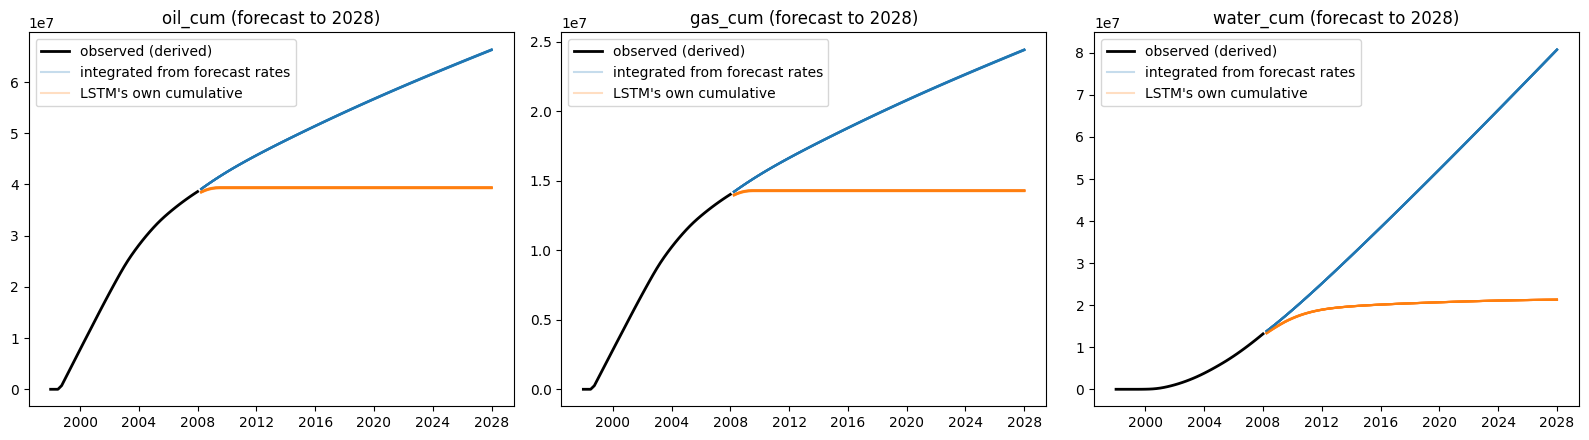

relative gap at 2028 between the two cumulatives (oil, gas, water): [0.486 0.492 0.736]


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for j, (ax, nm) in enumerate(zip(axes, CUMS)):
    ax.plot(EDA_obs['date'], EDA_obs[nm], 'k', lw=2, label='observed (derived)')
    for k in range(cum.shape[0]):
        ax.plot(dates, cum[k, :, j], color='tab:blue', alpha=.25, label='integrated from forecast rates' if k == 0 else None)
        own = np.maximum.accumulate(fc[k, 41:, 3 + j])                    # the LSTM's own cumulative, made non-decreasing
        ax.plot(dates, own, color='tab:orange', alpha=.25, label="LSTM's own cumulative" if k == 0 else None)
    ax.set_title(nm + ' (forecast to 2028)'); ax.legend()
plt.tight_layout(); plt.show()

gap = (np.abs(cum[:, -1, :] - fc[:, -1, 3:6]) / cum[:, -1, :]).mean(0)
print('relative gap at 2028 between the two cumulatives (oil, gas, water):', gap.round(3))

The blue curves are the ones to put in the template, because they follow the rates exactly. The gap line is a check. If it is under about 5%, the LSTM’s rates and cumulative agree. If it is large, the LSTM’s cumulative output has drifted, and that is another reason to forecast the rates only.

jump at 2008 (first forecast vs last observed): oil/gas/water = [ 0.061  0.069 -0.046] (want within about +-3%)
std of oil_cum at 2008 across cases: true = 2862947 | LSTM free-run = 3011432
cum oil at 2028: min/median/max = 65691049.0 65691066.0 65691088.0
ensemble spread of oil rate at 2028 (std/mean):  0.0


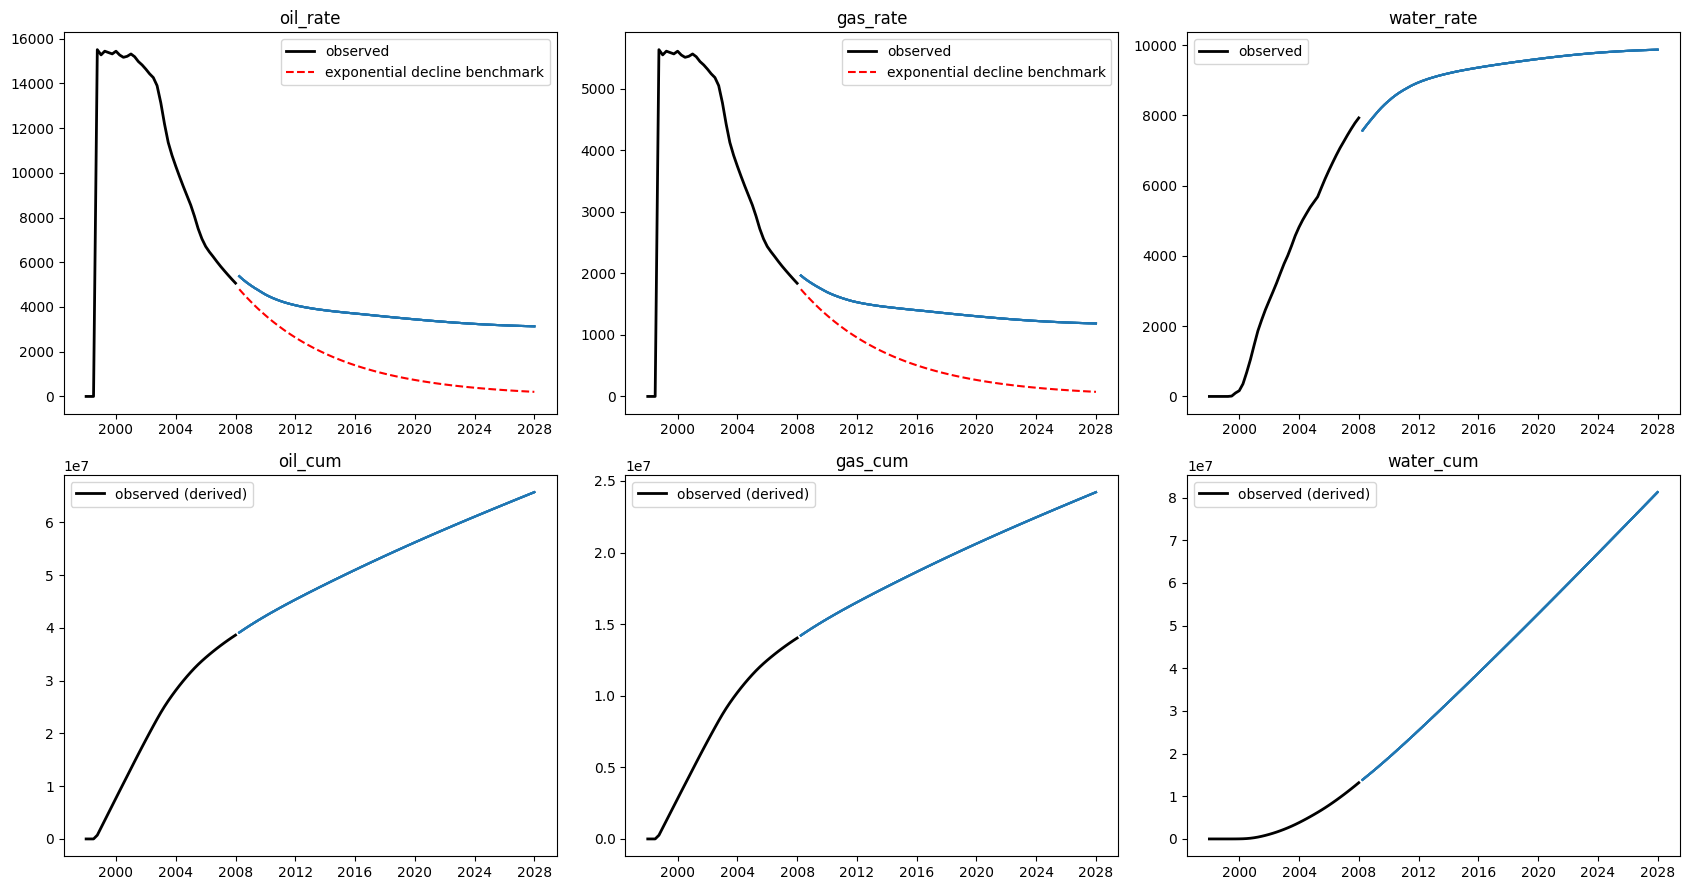

In [ ]:
import torch, numpy as np, pandas as pd, matplotlib.pyplot as plt

# --- 0) ensemble parameters (from Cell C/D) -> scaled static inputs
best = pd.read_parquet('history_match_top20.parquet')
S = torch.tensor(scaler_static.transform(best[PARAMS].to_numpy()), dtype=torch.float32)
n_future = 80
dates = pd.date_range('2008-04-01', periods=n_future, freq='QS')

# --- 1) WARM START: feed the REAL observed history, then roll out 80 quarters
obs_seq = scaler_seq.transform(EDA_obs[ALL].to_numpy())                  # (41, 6), scaled
model.eval()
with torch.no_grad():
    seq = torch.tensor(obs_seq[None], dtype=torch.float32).repeat(len(best), 1, 1)
    for _ in range(n_future):
        seq = torch.cat([seq, model(S, seq)[:, -1:, :]], dim=1)
fc = scaler_seq.inverse_transform(seq.numpy().reshape(-1, 6)).reshape(len(best), -1, 6)
rates = np.clip(fc[:, 41:, :3], 0, None)                                  # (20, 80, 3): oil, gas, water

# --- 2) cumulative from the forecast rates, starting at the last observed (derived) cumulative
all_dates = pd.DatetimeIndex([pd.Timestamp('2008-01-01')]).union(dates)
days = np.diff(all_dates.to_numpy()).astype('timedelta64[D]').astype(float)
cum0 = EDA_obs[['oil_cum', 'gas_cum', 'water_cum']].iloc[-1].to_numpy()
cum = cum0 + np.cumsum(rates * days[None, :, None], axis=1)

# --- 3) numbers to read
last_obs = EDA_obs[['oil_rate', 'gas_rate', 'water_rate']].iloc[-1].to_numpy()
jump = (rates[:, 0, :].mean(0) - last_obs) / last_obs
print('jump at 2008 (first forecast vs last observed): oil/gas/water =', jump.round(3), '(want within about +-3%)')
print('std of oil_cum at 2008 across cases: true =', round(Y['oil_cum'][:, -1].std()), '| LSTM free-run =', round(free[:, -1, 3].std()))
print('cum oil at 2028: min/median/max =', *np.round([cum[:, -1, 0].min(), np.median(cum[:, -1, 0]), cum[:, -1, 0].max()]))
print('ensemble spread of oil rate at 2028 (std/mean): ', round(rates[:, -1, 0].std() / rates[:, -1, 0].mean(), 4))

# --- 4) exponential-decline benchmark (oil and gas) from the last 12 observed quarters
bench = {}
for nm in ['oil_rate', 'gas_rate']:
    y = EDA_obs[nm].iloc[-12:].to_numpy(); b, a = np.polyfit(np.arange(12), np.log(y), 1)
    bench[nm] = np.exp(a + b * np.arange(12, 12 + n_future))

# --- 5) plots: rates and cumulative
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for j, nm in enumerate(['oil_rate', 'gas_rate', 'water_rate']):
    ax = axes[0, j]
    for k in range(len(best)): ax.plot(dates, rates[k, :, j], color='tab:blue', alpha=.25)
    ax.plot(EDA_obs['date'], EDA_obs[nm], 'k', lw=2, label='observed')
    if nm in bench: ax.plot(dates, bench[nm], 'r--', label='exponential decline benchmark')
    ax.set_title(nm); ax.legend()
for j, nm in enumerate(['oil_cum', 'gas_cum', 'water_cum']):
    ax = axes[1, j]
    for k in range(len(best)): ax.plot(dates, cum[k, :, j], color='tab:blue', alpha=.25)
    ax.plot(EDA_obs['date'], EDA_obs[nm], 'k', lw=2, label='observed (derived)'); ax.set_title(nm); ax.legend()
plt.tight_layout(); plt.show()

How to read the printout and plots

The jump line. Oil, gas and water should each be within about ±3%. Last time they were +12%, +14% and −7%. If they are now small, the warm start worked.
The two std numbers. If the LSTM std is far smaller than the true one, the LSTM ignores the parameters. Then do the ensemble with the GP, as I said before.
The spread of oil at 2028 should be well above 0.5%. A very small number means the ensemble members are still effectively one forecast.
The red dashed line shows where a pure decline would go. If the blue curves sit far above it and are flat, they are probably too optimistic. If they sit close to or below it and keep falling, they are more believable.
The cumulative row should be smooth and rising, starting where the black observed line ends. Any visible step at 2008 means the starting value cum0 is off.

This drops the warm start. It runs the LSTM from zero for many different parameter sets and scales each forecast so it starts at the last observed point. That removes the jump while keeping the parameter spread. The best ten are chosen by how well each member reproduces the observed history. It needs Cell D’s mismatch(…, keys) and match, plus lo, hi, qmc, RATES, obs, sequences, model, scaler_static and scaler_seq. The rollout part is untested here, because I have no PyTorch.

44387 candidates within 1.5x of the best GP mismatch
history rmse: best 0.1291 | median 0.1402 | worst 0.2022
ratio applied (oil/gas/water), median: [0.988 0.984 1.024]
oil rate at 2028, std/mean over all members: 0.179


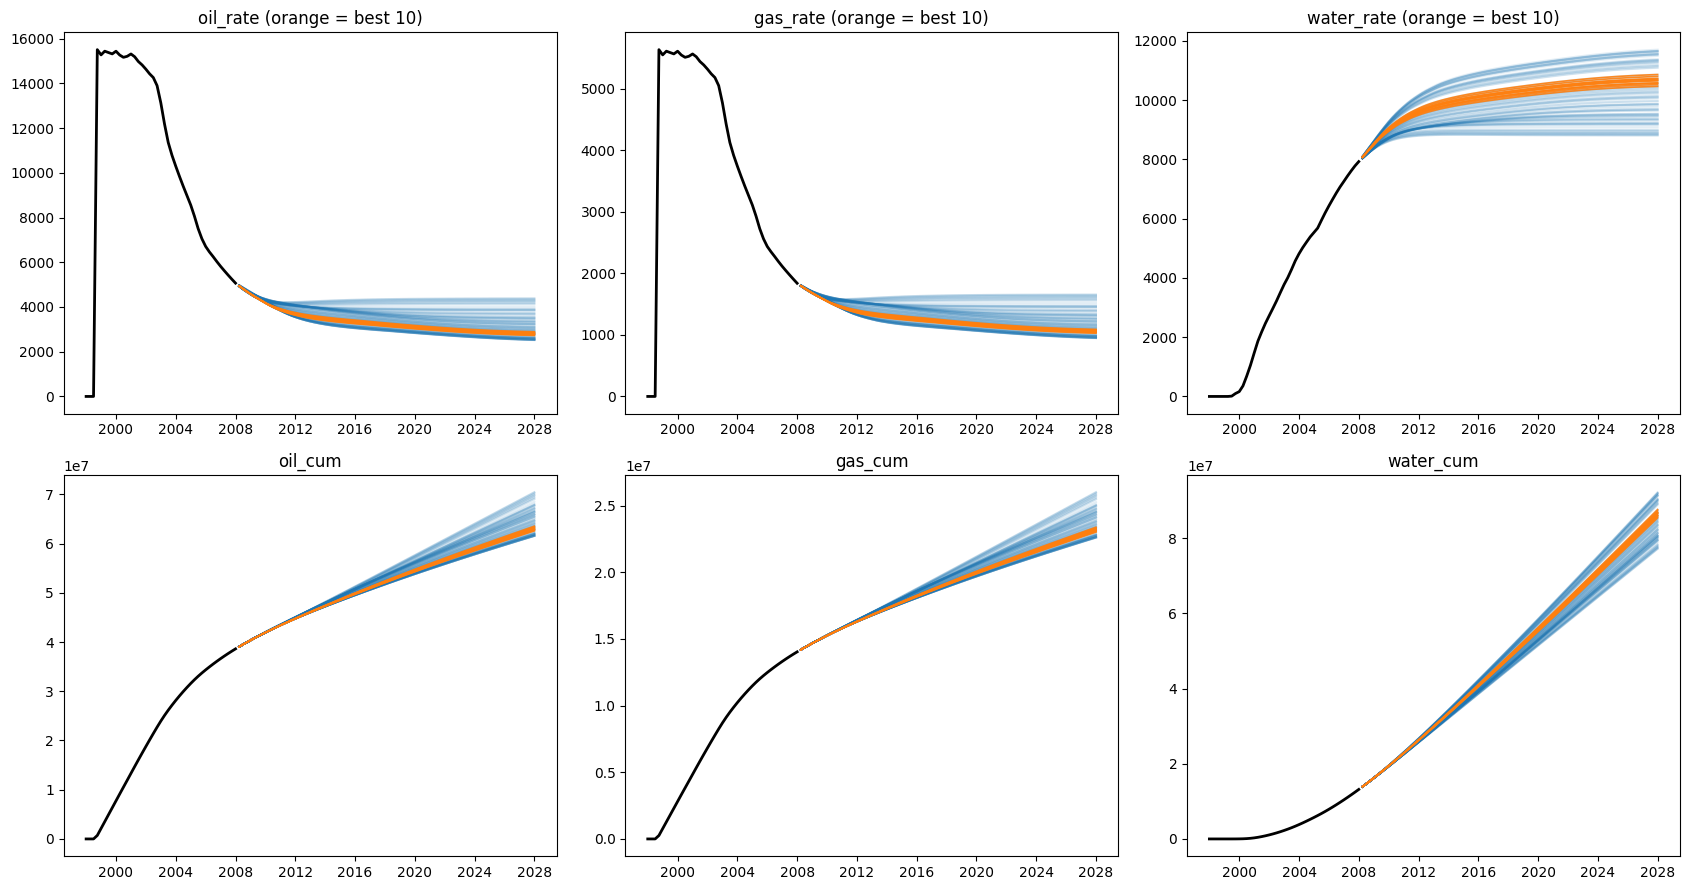

In [ ]:
# 1) many acceptable parameter sets, not just the 20 nearest the best point
cand = lo + qmc.LatinHypercube(d=4, seed=1).random(50000) * (hi - lo)
err = mismatch(xs.transform(cand), obs, RATES)
ok = np.where(err < 1.5 * err.min())[0]
print(len(ok), 'candidates within 1.5x of the best GP mismatch')
pick = np.random.default_rng(0).choice(ok, size=min(100, len(ok)), replace=False)
acc = pd.DataFrame(cand[pick], columns=PARAMS); acc['gp_mismatch'] = err[pick]

# 2) LSTM free-run from step 0: 40 history steps + 80 future steps
n_future = 80
S = torch.tensor(scaler_static.transform(acc[PARAMS].to_numpy()), dtype=torch.float32)
model.eval()
with torch.no_grad():
    seq = torch.tensor(sequences[:1, :1, :], dtype=torch.float32).repeat(len(acc), 1, 1)
    for _ in range(40 + n_future):
        seq = torch.cat([seq, model(S, seq)[:, -1:, :]], dim=1)
fc = scaler_seq.inverse_transform(seq.numpy().reshape(-1, 6)).reshape(len(acc), -1, 6)   # (n, 121, 6)

# 3) history fit of each member, and rebase the future to the last observed point
obs_r = EDA_obs[RATES].to_numpy().astype(np.float64)
hist = fc[:, :41, :3].astype(np.float64)
rmse = np.sqrt((((hist - obs_r) / obs_r.max(0)) ** 2).mean(axis=(1, 2)))
ratio = np.clip(obs_r[-1] / np.clip(hist[:, -1, :], 1e-6, None), 0.5, 2.0)
rates = np.clip(fc[:, 41:, :3].astype(np.float64) * ratio[:, None, :], 0, None)

dates = pd.date_range('2008-04-01', periods=n_future, freq='QS')
all_dates = pd.DatetimeIndex([pd.Timestamp('2008-01-01')]).union(dates)
days = np.diff(all_dates.to_numpy()).astype('timedelta64[D]').astype(float)
cum = EDA_obs[['oil_cum', 'gas_cum', 'water_cum']].iloc[-1].to_numpy().astype(np.float64) + np.cumsum(rates * days[None, :, None], axis=1)

# 4) best ten by history fit
top10 = np.argsort(rmse)[:10]
print('history rmse: best', rmse.min().round(4), '| median', np.median(rmse).round(4), '| worst', rmse.max().round(4))
print('ratio applied (oil/gas/water), median:', np.median(ratio, axis=0).round(3))
print('oil rate at 2028, std/mean over all members:', (rates[:, -1, 0].std() / rates[:, -1, 0].mean()).round(3))

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for j, nm in enumerate(['oil_rate', 'gas_rate', 'water_rate']):
    ax = axes[0, j]
    ax.plot(dates, rates[:, :, j].T, color='tab:blue', alpha=.12)
    ax.plot(dates, rates[top10, :, j].T, color='tab:orange', alpha=.9, lw=1.2)
    ax.plot(EDA_obs['date'], EDA_obs[nm], 'k', lw=2); ax.set_title(nm + ' (orange = best 10)')
for j, nm in enumerate(['oil_cum', 'gas_cum', 'water_cum']):
    ax = axes[1, j]
    ax.plot(dates, cum[:, :, j].T, color='tab:blue', alpha=.12)
    ax.plot(dates, cum[top10, :, j].T, color='tab:orange', alpha=.9, lw=1.2)
    ax.plot(EDA_obs['date'], EDA_obs[nm], 'k', lw=2); ax.set_title(nm)
plt.tight_layout(); plt.show()
acc.iloc[top10].assign(history_rmse=rmse[top10]).to_parquet('best10_params.parquet')

In [ ]:
S1 = torch.tensor(scaler_static.transform(best[PARAMS].to_numpy()[:5]), dtype=torch.float32)
with torch.no_grad():
    seq = torch.tensor(sequences[:1, :1, :], dtype=torch.float32).repeat(5, 1, 1)
    for _ in range(40): seq = torch.cat([seq, model(S1, seq)[:, -1:, :]], dim=1)
lstm_hist = scaler_seq.inverse_transform(seq.numpy().reshape(-1, 6)).reshape(5, 41, 6)[:, :, :3]
gp_hist = np.stack([proxy6[v](xs.transform(best[PARAMS].to_numpy()[:5])) for v in RATES], axis=2)
obs_r = EDA_obs[RATES].to_numpy()
print('last-step oil rate: observed', round(obs_r[-1, 0], 0), '| GP', gp_hist[:, -1, 0].round(0), '| LSTM', lstm_hist[:, -1, 0].round(0))

last-step oil rate: observed 5067.0 | GP [5616. 5615. 5582. 5569. 5602.] | LSTM [5860. 5821. 5870. 5877. 5867.]




---

### Part 8: Data Reassessment and Prediction

In [ ]:
#1. Is the observed curve even inside what the simulator can produce?
for v in RATES:
    tail = Y[v][:, -5:].astype(float)
    print(v, '| observed last 5:', EDA_obs[v].iloc[-5:].round(0).to_numpy(),
          '| sim min:', tail.min(0).round(0), '| sim max:', tail.max(0).round(0))

oil_rate | observed last 5: [5819. 5624. 5433. 5247. 5067.] | sim min: [3418. 3339. 3258. 3182. 3108.] | sim max: [7062. 6937. 6817. 6692. 6566.]
gas_rate | observed last 5: [2114. 2043. 1974. 1906. 1839.] | sim min: [1241. 1213. 1183. 1155. 1129.] | sim max: [2566. 2520. 2477. 2431. 2386.]
water_rate | observed last 5: [7257. 7440. 7616. 7782. 7926.] | sim min: [6042. 6139. 6248. 6357. 6463.] | sim max: [8734. 8838. 8967. 9087. 9186.]


In [ ]:
#2. The unexplained RAMP_History column in the simulated sheets
import glob
f = glob.glob('/content/drive/MyDrive/**/02_*Oil_production_rate*.parquet', recursive=True)[0]
raw = pd.read_parquet(f)
names = [str(x).strip() for x in raw.iloc[1]]
c = names.index('RAMP_History')
ramp = pd.Series(pd.to_numeric(raw.iloc[3:, c], errors='coerce').values,
                 index=pd.to_datetime(raw.iloc[3:, 0], format='mixed', errors='coerce')).dropna()
print(len(ramp), ramp.index.min().date(), '->', ramp.index.max().date()); print(ramp.tail(5))
print('observed oil_rate tail:'); print(EDA_obs[['date', 'oil_rate']].tail(5))

41 1998-01-01 -> 2008-01-01
c0
2007-01-01    5818.849
2007-04-01    5624.407
2007-07-01    5433.262
2007-10-01    5246.799
2008-01-01    5066.679
dtype: Float64
observed oil_rate tail:
         date  oil_rate
36 2007-01-01  5818.849
37 2007-04-01  5624.407
38 2007-07-01  5433.262
39 2007-10-01  5246.799
40 2008-01-01  5066.679


In [ ]:
W = np.linspace(1, 5, 41)                      # later quarters count up to 5x
def mismatch(Xs_batch, obs, keys, w=W):
    e = 0
    for v in keys:
        obs_val = obs[v].astype(np.float64)
        pred_val = proxy6[v](Xs_batch).astype(np.float64)
        e = e + ((((pred_val - obs_val) / obs_val.max()) ** 2) * w).sum(axis=1) / w.sum()
    return np.sqrt(e / len(keys))

# Ensure we cast the dictionary values in Y and obs to float64 to prevent object dtype mathematical issues
Y_numeric = {v: Y[v].astype(np.float64) for v in Y}
obs_numeric = {v: obs[v].astype(np.float64) for v in RATES}

# A) The 100 REAL simulated cases scored against the observed history with the same weighted objective
sim_err = np.sqrt(sum((((Y_numeric[v] - obs_numeric[v]) / obs_numeric[v].max()) ** 2 * W).sum(1) / W.sum() for v in RATES) / 3)
t5 = np.argsort(sim_err)[:5]
tab = cases.loc[t5, ['case_id', 'split'] + PARAMS].assign(err=sim_err[t5].round(4),
        oil_last=Y_numeric['oil_rate'][t5, -1].round(0), gas_last=Y_numeric['gas_rate'][t5, -1].round(0), water_last=Y_numeric['water_rate'][t5, -1].round(0))
display(tab)
print('observed last step: oil', obs_numeric['oil_rate'][-1].round(0), '| gas', obs_numeric['gas_rate'][-1].round(0), '| water', obs_numeric['water_rate'][-1].round(0))

# B) The proxy-based match with the weighted objective, three seeds, more samples
runs = [match(obs_numeric, RATES, n_samples=50000, seed=s) for s in range(3)]
ens, eerr, bx, bf = min(runs, key=lambda r: r[3])
print('proxy match error', round(bf, 4), '| best real simulated case error', round(sim_err.min(), 4))
print('proxy best parameters', dict(zip(PARAMS, bx.round(3))))
print('GP at best, last step: oil', proxy6['oil_rate'](xs.transform(bx[None, :]))[0, -1].round(0),
      '| gas', proxy6['gas_rate'](xs.transform(bx[None, :]))[0, -1].round(0),
      '| water', proxy6['water_rate'](xs.transform(bx[None, :]))[0, -1].round(0))

,case_id,split,fault_trans,poro_mult,perm_mult,aquifer_pv,err,oil_last,gas_last,water_last
64,65,train,0.074626,1.290918,2.396347,163.13303,0.0887,5577.0,2027.0,7268.0
68,69,train,0.14995,1.265749,4.325475,107.333293,0.0887,5623.0,2043.0,7290.0
18,19,train,0.101141,1.23684,8.763611,82.994324,0.0892,5728.0,2077.0,7301.0
31,32,train,0.1441,1.225992,8.253429,97.073275,0.0892,5654.0,2051.0,7375.0
98,99,test,0.08655,1.210052,6.491994,60.221259,0.0893,5472.0,1988.0,7306.0


observed last step: oil 5067.0 | gas 1839.0 | water 7926.0
proxy match error 0.0885 | best real simulated case error 0.0887
proxy best parameters {'fault_trans': np.float64(0.118), 'poro_mult': np.float64(1.309), 'perm_mult': np.float64(0.82), 'aquifer_pv': np.float64(197.639)}
GP at best, last step: oil 5584.0 | gas 2025.0 | water 7289.0


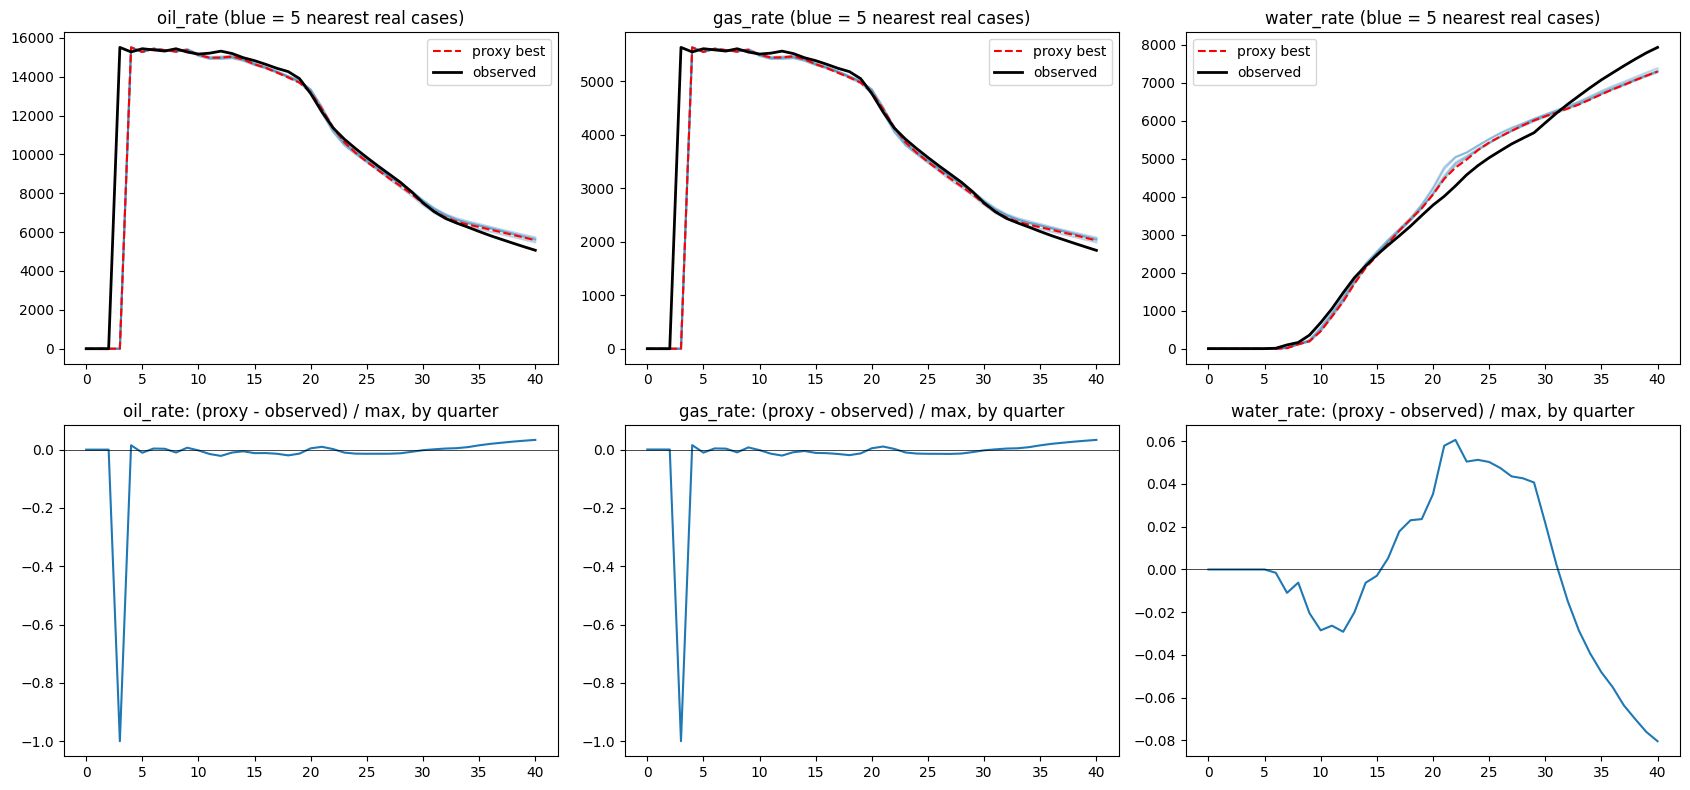

error with ranges widened 30%: 0.0884 (was 0.0885 ) | params {'fault_trans': np.float64(0.104), 'poro_mult': np.float64(1.254), 'perm_mult': np.float64(12.5), 'aquifer_pv': np.float64(147.417)}


In [ ]:
import matplotlib.pyplot as plt
best_curves = {v: proxy6[v](xs.transform(bx[None, :]))[0] for v in RATES}

# 1) Where is the mismatch in time?
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for j, v in enumerate(RATES):
    ax = axes[0, j]
    ax.plot(Y[v][t5].T, color='tab:blue', alpha=.3)
    ax.plot(best_curves[v], 'r--', label='proxy best'); ax.plot(obs[v], 'k', lw=2, label='observed')
    ax.set_title(v + ' (blue = 5 nearest real cases)'); ax.legend()
    axes[1, j].plot((best_curves[v] - obs[v]) / obs[v].max()); axes[1, j].axhline(0, color='k', lw=.5)
    axes[1, j].set_title(v + ': (proxy - observed) / max, by quarter')
plt.tight_layout(); plt.show()

# 2) Does the error drop if the parameter ranges are widened by 30%? (GP extrapolation, diagnostic only)
lo0, hi0 = lo.copy(), hi.copy()
lo = np.maximum(lo0 - 0.3 * (hi0 - lo0), 1e-3); hi = hi0 + 0.3 * (hi0 - lo0)
_, _, bx2, bf2 = match(obs, RATES, n_samples=50000, seed=0)
lo, hi = lo0, hi0
print('error with ranges widened 30%:', round(bf2, 4), '(was', round(bf, 4), ') | params', dict(zip(PARAMS, bx2.round(3))))

In [ ]:
W = np.r_[np.zeros(6), np.linspace(1, 5, 35)]          # skip quarters 0-5, weight later quarters up to 5x

# Ensure we cast dictionary values to float64 to avoid object dtype mathematical errors
Y_numeric = {v: Y[v].astype(np.float64) for v in Y}
obs_numeric = {v: obs[v].astype(np.float64) for v in RATES}

def mismatch(Xs_batch, obs_dict, keys, w=W):
    e = 0
    for v in keys:
        true_val = obs_dict[v].astype(np.float64)
        pred_val = proxy6[v](Xs_batch).astype(np.float64)
        e = e + ((((pred_val - true_val) / true_val.max()) ** 2) * w).sum(axis=1) / w.sum()
    return np.sqrt(e / len(keys))

sim_err = np.sqrt(sum((((Y_numeric[v] - obs_numeric[v]) / obs_numeric[v].max()) ** 2 * W).sum(1) / W.sum() for v in RATES) / 3)
t5 = np.argsort(sim_err)[:5]
print('best real simulated cases:', cases.loc[t5, 'case_id'].tolist(), sim_err[t5].round(4))

runs = [match(obs_numeric, RATES, n_samples=50000, seed=s) for s in range(3)]
ens, eerr, bx, bf = min(runs, key=lambda r: r[3])
print('proxy match error', round(bf, 4), '| best real case', round(sim_err.min(), 4))
print('params', dict(zip(PARAMS, bx.round(3))))
for v in RATES:
    print(v, 'last step: proxy', proxy6[v](xs.transform(bx[None, :]))[0, -1].round(0), '| observed', obs_numeric[v][-1].round(0))

# widened-range test again (now it means something)
lo0, hi0 = lo.copy(), hi.copy()
lo = np.maximum(lo0 - 0.3 * (hi0 - lo0), 1e-3); hi = hi0 + 0.3 * (hi0 - lo0)
_, _, bx2, bf2 = match(obs_numeric, RATES, n_samples=50000, seed=0)
lo, hi = lo0, hi0
print('error with ranges widened 30%:', round(bf2, 4), '| params', dict(zip(PARAMS, bx2.round(3))))

best real simulated cases: [65, 69, 32, 19, 2] [0.0303 0.0304 0.0317 0.0318 0.0319]
proxy match error 0.0291 | best real case 0.0303
params {'fault_trans': np.float64(0.153), 'poro_mult': np.float64(1.24), 'perm_mult': np.float64(12.564), 'aquifer_pv': np.float64(108.586)}
oil_rate last step: proxy 5545.0 | observed 5067.0
gas_rate last step: proxy 2018.0 | observed 1839.0
water_rate last step: proxy 7303.0 | observed 7926.0
error with ranges widened 30%: 0.029 | params {'fault_trans': np.float64(0.042), 'poro_mult': np.float64(1.251), 'perm_mult': np.float64(12.999), 'aquifer_pv': np.float64(126.962)}


7995 accepted candidates (error < 0.0438 )
history rmse: best 0.0308 | median 0.0378
ratio applied (oil/gas/water), median: [0.886 0.883 1.086]
cum oil 2028 P10/P50/P90 (all members): [62138282. 62905075. 63972758.]
cum oil 2028 of the 10 chosen: [62683213. 62798226. 62849906. 62956186. 63032897. 63151437. 63162887.
 63351637. 63440621. 63508124.]


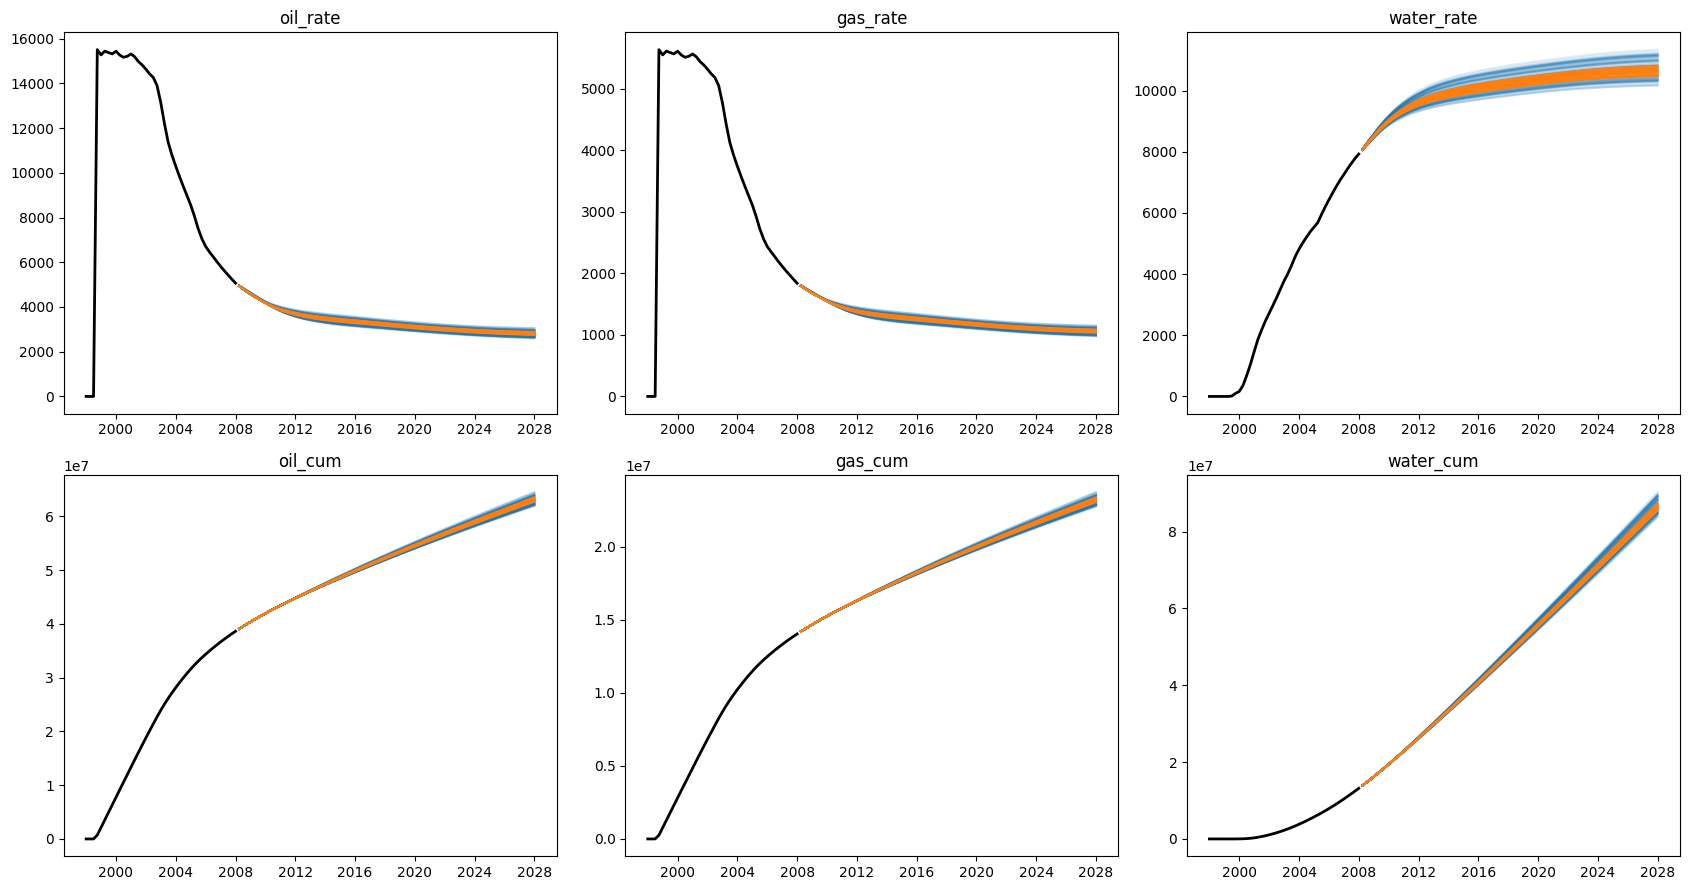

In [ ]:
import torch
# 1) accepted parameter sets within 1.5x of the best error (original ranges)
cand = lo + qmc.LatinHypercube(d=4, seed=1).random(50000) * (hi - lo)
err = mismatch(xs.transform(cand), obs, RATES)
ok = np.where(err < 1.5 * err.min())[0]
print(len(ok), 'accepted candidates (error <', round(1.5 * err.min(), 4), ')')
pick = np.random.default_rng(0).choice(ok, size=min(100, len(ok)), replace=False)
acc = pd.DataFrame(cand[pick], columns=PARAMS); acc['gp_mismatch'] = err[pick]

# 2) LSTM free-run from step 0: 40 history steps + 80 future steps
n_future = 80
S = torch.tensor(scaler_static.transform(acc[PARAMS].to_numpy()), dtype=torch.float32)
model.eval()
with torch.no_grad():
    seq = torch.tensor(sequences[:1, :1, :], dtype=torch.float32).repeat(len(acc), 1, 1)
    for _ in range(40 + n_future):
        seq = torch.cat([seq, model(S, seq)[:, -1:, :]], dim=1)
fc = scaler_seq.inverse_transform(seq.numpy().reshape(-1, 6)).reshape(len(acc), -1, 6)

# 3) history fit of each member (start-up quarters ignored), rebase the future to the last observed point
obs_r = EDA_obs[RATES].to_numpy().astype(np.float64)
fc_hist = fc[:, :41, :3].astype(np.float64)
W_numeric = W.astype(np.float64)
res = ((fc_hist - obs_r) / obs_r.max(0)) ** 2
rmse = np.sqrt(((res * W_numeric[None, :, None]).sum(1) / W_numeric.sum()).mean(1))
ratio = np.clip(obs_r[-1] / np.clip(fc[:, 40, :3].astype(np.float64), 1e-6, None), 0.5, 2.0)
rates = np.clip(fc[:, 41:, :3].astype(np.float64) * ratio[:, None, :], 0, None)
dates = pd.date_range('2008-04-01', periods=n_future, freq='QS')

# Ensure a clean datetime64 array for np.diff
all_dates = pd.DatetimeIndex([pd.Timestamp('2008-01-01')]).union(dates).to_numpy()
days = np.diff(all_dates).astype('timedelta64[D]').astype(float)
cum = EDA_obs[['oil_cum', 'gas_cum', 'water_cum']].iloc[-1].to_numpy().astype(np.float64) + np.cumsum(rates * days[None, :, None], axis=1)

# 4) ten lines that cover the range: the 30 best by history fit, spread evenly over 2028 cumulative oil
best30 = np.argsort(rmse)[:30]
by_cum = best30[np.argsort(cum[best30, -1, 0])]
top10 = by_cum[np.linspace(0, len(by_cum) - 1, 10).round().astype(int)]
print('history rmse: best', rmse.min().round(4), '| median', np.median(rmse).round(4))
print('ratio applied (oil/gas/water), median:', np.median(ratio, axis=0).round(3))
print('cum oil 2028 P10/P50/P90 (all members):', np.percentile(cum[:, -1, 0], [10, 50, 90]).round(0))
print('cum oil 2028 of the 10 chosen:', np.sort(cum[top10, -1, 0]).round(0))

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for j, nm in enumerate(['oil_rate', 'gas_rate', 'water_rate']):
    ax = axes[0, j]; ax.plot(dates, rates[:, :, j].T, color='tab:blue', alpha=.12)
    ax.plot(dates, rates[top10, :, j].T, color='tab:orange', lw=1.3); ax.plot(EDA_obs['date'], EDA_obs[nm], 'k', lw=2); ax.set_title(nm)
for j, nm in enumerate(['oil_cum', 'gas_cum', 'water_cum']):
    ax = axes[1, j]; ax.plot(dates, cum[:, :, j].T, color='tab:blue', alpha=.12)
    ax.plot(dates, cum[top10, :, j].T, color='tab:orange', lw=1.3); ax.plot(EDA_obs['date'], EDA_obs[nm], 'k', lw=2); ax.set_title(nm)
plt.tight_layout(); plt.show()
acc.iloc[top10].assign(history_rmse=rmse[top10]).to_parquet('best10_params.parquet')

What the plot shows

No jump at 2008. Every line starts at the last observed point.
A real fan. Cumulative oil at 2028 has P10/P50/P90 of 62.1M / 62.9M / 64.0M, and the ten chosen lines run from 62.7M to 63.5M. The rate fan at 2028 is about 2,700–3,000 for oil and about 10,000–11,000 for water. The ten chosen lines are spread across the fan, not clustered.
Water keeps rising and then flattens, which fits the observed trend. Oil and gas decline smoothly.

Two caveats to write into the deck

The rebasing carries weight. The median correction factors are 0.886 (oil), 0.883 (gas) and 1.086 (water). Before rebasing, the LSTM was about 12% off at 2008, so the forecast levels depend on that correction.
The fan is narrower than the real uncertainty. All lines share one LSTM-learned shape, and oil flattens near 3,000 STB/d. The exponential-decline benchmark we drew earlier falls far below that. By my rough estimate, a continued decline would add about half as much oil after 2008 as the LSTM does. If the hidden data declines like that, it would fall outside this fan. Say this plainly as a limitation. If time remains, add a second family of lines with a steeper decline.

In [ ]:
#write into template
import openpyxl
TEMPLATE = str(BASE / 'xlsx' / '09 Template Deliverable.xlsx')          # path of the updated template
OUT = '/content/Template_filled.xlsx'
order10 = top10[np.argsort(rmse[top10])]        # Case 1 = best history fit
fc_day = {d.normalize(): i for i, d in enumerate(dates)}
wb = openpyxl.load_workbook(TEMPLATE); print(wb.sheetnames)
for k, member in enumerate(order10, start=1):
    ws = wb[f'Case {k}']
    hdr_row = next(r for r in range(1, 15) if any('date' in str(c.value).lower() for c in ws[r] if c.value))
    cols = {}
    for c in ws[hdr_row]:
        t = str(c.value).lower() if c.value else ''
        for key in ('date', 'oil', 'gas', 'water'):
            if key in t and (key == 'date' or 'cum' in t): cols[key] = c.column
    assert set(cols) == {'date', 'oil', 'gas', 'water'}, f'Case {k}: could not map columns {cols}; header = {[c.value for c in ws[hdr_row]]}'
    n_ok, missing = 0, []
    for r in range(hdr_row + 1, ws.max_row + 1):
        v = ws.cell(r, cols['date']).value
        if v in (None, ''): continue
        d = pd.to_datetime(v, format='%m/%d/%Y', errors='coerce') if isinstance(v, str) else pd.Timestamp(v)
        i = fc_day.get(d.normalize()) if pd.notna(d) else None
        if i is None: missing.append(v); continue
        ws.cell(r, cols['oil']).value = float(cum[member, i, 0])
        ws.cell(r, cols['gas']).value = float(cum[member, i, 1])
        ws.cell(r, cols['water']).value = float(cum[member, i, 2]); n_ok += 1
    print(f'Case {k}: member {member} | columns {cols} | rows filled {n_ok} | dates not matched {missing[:3]}')
wb.save(OUT)
from google.colab import files; files.download(OUT)

['Case 1', 'Case 2', 'Case 3', 'Case 4', 'Case 5', 'Case 6', 'Case 7', 'Case 8', 'Case 9', 'Case 10']
Case 1: member 63 | columns {'date': 1, 'gas': 2, 'oil': 3, 'water': 4} | rows filled 80 | dates not matched []
Case 2: member 92 | columns {'date': 1, 'gas': 2, 'oil': 3, 'water': 4} | rows filled 80 | dates not matched []
Case 3: member 93 | columns {'date': 1, 'gas': 2, 'oil': 3, 'water': 4} | rows filled 80 | dates not matched []
Case 4: member 86 | columns {'date': 1, 'gas': 2, 'oil': 3, 'water': 4} | rows filled 80 | dates not matched []
Case 5: member 28 | columns {'date': 1, 'gas': 2, 'oil': 3, 'water': 4} | rows filled 80 | dates not matched []
Case 6: member 52 | columns {'date': 1, 'gas': 2, 'oil': 3, 'water': 4} | rows filled 80 | dates not matched []
Case 7: member 67 | columns {'date': 1, 'gas': 2, 'oil': 3, 'water': 4} | rows filled 80 | dates not matched []
Case 8: member 5 | columns {'date': 1, 'gas': 2, 'oil': 3, 'water': 4} | rows filled 80 | dates not matched []
Cas

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
#quick check
import openpyxl
wb = openpyxl.load_workbook('/content/Template_filled.xlsx')
for k in range(1, 11):
    ws = wb[f'Case {k}']
    rows = [[c.value for c in r] for r in ws.iter_rows(min_row=2) if r[0].value]
    arr = np.array([r[1:4] for r in rows], dtype=float)
    ok = (np.diff(arr, axis=0) >= 0).all()                      # cumulative must never decrease
    print(f'Case {k}: {len(rows)} rows | {rows[0][0]} -> {rows[-1][0]} | monotonic: {ok} | last (gas, oil, water):', arr[-1].round(0))
print('header:', [c.value for c in wb['Case 1'][1]])

Case 1: 80 rows | 04/01/2008 -> 2028-01-01 00:00:00 | monotonic: True | last (gas, oil, water): [23230237. 63162887. 86204114.]
Case 2: 80 rows | 04/01/2008 -> 2028-01-01 00:00:00 | monotonic: True | last (gas, oil, water): [23225524. 63151437. 86230152.]
Case 3: 80 rows | 04/01/2008 -> 2028-01-01 00:00:00 | monotonic: True | last (gas, oil, water): [23181273. 63032897. 86479975.]
Case 4: 80 rows | 04/01/2008 -> 2028-01-01 00:00:00 | monotonic: True | last (gas, oil, water): [23151718. 62956186. 86663274.]
Case 5: 80 rows | 04/01/2008 -> 2028-01-01 00:00:00 | monotonic: True | last (gas, oil, water): [23301626. 63351637. 85818893.]
Case 6: 80 rows | 04/01/2008 -> 2028-01-01 00:00:00 | monotonic: True | last (gas, oil, water): [23110981. 62849906. 86926316.]
Case 7: 80 rows | 04/01/2008 -> 2028-01-01 00:00:00 | monotonic: True | last (gas, oil, water): [23091588. 62798226. 87057699.]
Case 8: 80 rows | 04/01/2008 -> 2028-01-01 00:00:00 | monotonic: True | last (gas, oil, water): [2333617

In [ ]:
import shutil
from pathlib import Path

# 1. Define paths
local_file = Path('/content/Template_filled.xlsx')
gdrive_destination = BASE / 'xlsx' / 'Template_filled.xlsx'

# 2. Copy to Google Drive
shutil.copy(local_file, gdrive_destination)
print(f"[GDRIVE] Successfully saved to Google Drive at: {gdrive_destination}")

# 3. Upload to GitHub
gh_upload(local_file, 'clean/Template_filled.xlsx', 'Add filled template deliverable')
print(f"[GITHUB] Successfully uploaded to repository path: clean/Template_filled.xlsx")


[GDRIVE] Successfully saved to Google Drive at: /content/drive/MyDrive/dw26/xlsx/Template_filled.xlsx
uploaded clean/Template_filled.xlsx (0.1 MB)
[GITHUB] Successfully uploaded to repository path: clean/Template_filled.xlsx
